# Milestone Pengembangan Sistem Prediksi Indikasi Kelainan Mata Berdasarkan Analisis Citra Mata

**Kelas:** *(IF-A)*  |  
**Status Registry:** *(LOCKED)* |  
**Tim:** *(Kevin Al Kautsar - 231110461, Winny Wijaya - 231110992, Michael Khosasi - 221111338)* |  
**Pendekatan:** *Classical Machine Learning* |  
**Domain:** Kesehatan mata / citra fundus (3 kelas) dan foto mata bagian luar (cataract)  |  
**Target:** `cataract`, `diabetic_retinopathy`, `glaucoma`, `normal` |

## Daftar Isi

| Kode | Bagian |
|---|---|
| A | Problem Formulation |
| B | Dataset dan Sumber Data |
| B.1 | Data Understanding |
| B.2 | Exploratory Data Analysis (EDA) |
| C | Preprocessing |
| C.1 | Feature Engineering Awal |
| D | Baseline |
| E | Kandidat Model Awal |
| F | Strategi Evaluasi |
| G | Ensemble: Perbandingan dengan Model Awal |
| H | Hasil Eksperimen Awal |
| I | Diagnosis Awal |
| J | Rencana Pengembangan Setelah UTS |

**Petunjuk menjalankan:** Google Colab → *Runtime → Run all*. Gunakan runtime CPU; GPU tidak diwajibkan. Internet diperlukan jika dataset belum tersedia dan notebook harus mengunduhnya melalui `kagglehub`. Jalankan semua sel dari atas ke bawah. Ekstraksi fitur citra dan eksperimen model dapat membutuhkan waktu.

**Catatan integritas:** semua angka, tabel, grafik, dan kesimpulan yang bergantung pada data dihasilkan oleh kode saat notebook dijalankan. Jangan mengisi angka secara manual. Sebelum dikumpulkan, simpan notebook setelah *Run all* berhasil agar output eksperimen ikut tersimpan.

## 0. Setup dan Konfigurasi

In [ ]:
import os, sys, hashlib, warnings, platform, importlib.util, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import sklearn
from PIL import Image
from joblib import Parallel, delayed
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import RidgeClassifier, LogisticRegression, SGDClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
try:
    from sklearn.linear_model import PassiveAggressiveClassifier
except ImportError:  # fallback untuk versi scikit-learn yang tidak menyediakan estimator ini
    PassiveAggressiveClassifier = None
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- Konfigurasi eksperimen ----
RANDOM_STATE = 42
N_JOBS = -1
LABEL_ORDER = ["cataract", "diabetic_retinopathy", "glaucoma", "normal"]
SPLITS = ("train", "val", "test")
N_SPLITS = 5
PERSENTIL_LAP_VAR = 0.95  # hanya untuk menandai 5% nilai lap_var tertinggi, bukan diagnosis noise
DHASH_MAX, SSIM_MIN = 1, 0.98
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1": "f1_macro", "ba": "balanced_accuracy", "acc": "accuracy"}

# ---- Fungsi bantu evaluasi & model ----
def metrik(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

def buat_model(nama, param, y_latih):
    """Pabrik model. Scaler/PCA berada di Pipeline agar hanya belajar dari fold/data latih."""
    k = np.sort(pd.Series(y_latih).unique())
    prior = np.full(len(k), 1.0 / len(k))
    if nama == "SVM RBF":
        return Pipeline([("sc", StandardScaler()),
                         ("m", SVC(kernel="rbf", C=float(param), class_weight="balanced"))])
    if nama == "Extra Trees":
        return ExtraTreesClassifier(n_estimators=300, max_features=param, class_weight="balanced",
                                    random_state=RANDOM_STATE, n_jobs=-1)
    if nama == "LDA":
        return Pipeline([("sc", StandardScaler()),
                         ("m", LinearDiscriminantAnalysis(solver="lsqr", shrinkage=param, priors=prior))])
    if nama == "QDA":
        # Komponen dibatasi berdasarkan jumlah sampel terkecil yang tersisa di
        # training fold Stratified K-Fold, bukan hanya jumlah pada data penuh.
        min_kelas = int(pd.Series(y_latih).value_counts().min())
        min_train_fold = min_kelas - int(np.ceil(min_kelas / N_SPLITS))
        n_pc = min(32, min_train_fold - 1)
        if n_pc < 1:
            raise ValueError("Jumlah sampel per kelas tidak cukup untuk QDA/PCA pada CV.")
        return Pipeline([("sc", StandardScaler()),
                         ("pca", PCA(n_components=n_pc, random_state=RANDOM_STATE)),
                         ("m", QuadraticDiscriminantAnalysis(reg_param=float(param), priors=prior))])
    if nama == "Ridge Classifier":
        return Pipeline([("sc", StandardScaler()),
                         ("m", RidgeClassifier(alpha=float(param), class_weight="balanced"))])
    if nama == "Passive-Aggressive":
        if PassiveAggressiveClassifier is not None:
            pa = PassiveAggressiveClassifier(C=float(param), max_iter=3000, tol=1e-3,
                                             class_weight="balanced", random_state=RANDOM_STATE)
        else:
            # Padanan berbasis SGD dengan loss hinge dan learning rate PA-I.
            pa = SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1", eta0=float(param),
                               max_iter=3000, tol=1e-3, class_weight="balanced", random_state=RANDOM_STATE)
        return Pipeline([("sc", StandardScaler()), ("m", pa)])
    if nama == "Logistic Regression":
        return Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(C=float(param), max_iter=3000, class_weight="balanced"))])
    if nama == "Dummy":
        return DummyClassifier(strategy="most_frequent")
    raise ValueError(f"Model tidak dikenal: {nama}")

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| OpenCV", cv2.__version__)
print(f"Seed={RANDOM_STATE} | CV=Stratified {N_SPLITS}-Fold | metrik utama=Macro F1")

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | OpenCV 5.0.0
Seed=42 | CV=Stratified 5-Fold | metrik utama=Macro F1


# A. Problem Formulation

- **Masalah:** membangun model yang mengklasifikasikan citra pada dataset ke dalam empat label yang tersedia: `cataract`, `diabetic_retinopathy`, `glaucoma`, dan `normal`.
- **Konteks:** klasifikasi citra berlabel dapat menjadi eksperimen awal untuk memahami pola visual pada dataset kelainan mata. Hasilnya tidak boleh diperlakukan sebagai diagnosis atau rekomendasi klinis.
- **Konteks penggunaan:** hasil hanya untuk eksperimen akademik. Jika kelak dipakai sebagai alat skrining, kesalahan paling merugikan adalah kelainan (mis. `glaucoma`, `diabetic_retinopathy`) yang diprediksi `normal`, sehingga recall per kelas ikut dilaporkan pada bagian I.
- **Tujuan:** membangun pipeline *supervised multi-class classification* dari citra menjadi fitur numerik, membandingkan baseline, enam algoritma *Classical Machine Learning*, dan satu pendekatan ensemble.
- **Unit observasi:** satu file citra. **Target:** label kelas yang diperoleh dari struktur folder dataset.
- **Modalitas data:** dataset bercampur. Kelas `diabetic_retinopathy`, `glaucoma`, dan `normal` berupa citra fundus (retina), sedangkan `cataract` berupa foto mata bagian luar (lihat B.2a). Karena itu skor 4 kelas dan skor 3 kelas fundus dilaporkan terpisah pada bagian I.
- **Fitur:** ekstraksi manual berupa statistik warna, ketajaman/tepi, tekstur, dan Histogram of Oriented Gradients (HOG); tidak menggunakan deep learning sebagai metode utama.
- **Alasan pendekatan Classical ML:** sesuai ruang lingkup mata kuliah; data 6.086 citra 224×224 cukup untuk fitur manual dan model klasik di CPU; fitur manual per kelompok (warna, tepi, tekstur, HOG) memungkinkan analisis kontribusi yang dapat dijelaskan (lihat I.b).
- **Metrik utama:** Macro F1 karena setiap kelas diberi bobot yang sama; Balanced Accuracy dan Accuracy dilaporkan sebagai metrik pendukung.
- **Batasan:** kualitas label dan sumber citra mengikuti dataset. Label tidak diverifikasi secara independen oleh tenaga medis; model hanya dievaluasi sebagai eksperimen akademik.

# B. Dataset dan Sumber Data

- **Sumber:** [Eye Disease Classification – Fundus Image Dataset](https://www.kaggle.com/datasets/mahin661/eye-disease-classification-fundus-image-dataset), Kaggle, pengunggah `mahin661`.
- **Lisensi:** https://creativecommons.org/licenses/by/4.0/ CC BY 4.0.
- **Unit data:** satu file citra; label dibaca dari nama folder kelas dan split dibaca dari folder `train`, `val`, atau `test`.
- **Fitur mentah:** citra digital. Kolom numerik untuk pemodelan dibuat sendiri pada bagian C.1, bukan diberikan sebagai tabel fitur oleh sumber dataset.
- **Pengambilan data:** sel berikut membaca lokasi lokal dari `EYE_DATA_DIR`. Jika variabel tersebut belum diatur, dataset diunduh menggunakan `kagglehub`.

In [ ]:
DATA_DIR = os.environ.get("EYE_DATA_DIR")
if not DATA_DIR:
    if importlib.util.find_spec("kagglehub") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "kagglehub"])
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("mahin661/eye-disease-classification-fundus-image-dataset")
print("Lokasi data:", DATA_DIR)

baris = []
for folder, _, files in os.walk(DATA_DIR):
    split = os.path.basename(os.path.dirname(folder))
    label = os.path.basename(folder)
    if split not in SPLITS or label not in LABEL_ORDER:
        continue
    for nama in files:
        if nama.lower().endswith((".jpg", ".jpeg", ".png")):
            baris.append({"path": os.path.join(folder, nama), "label": label, "split": split})

df = pd.DataFrame(baris)
if df.empty:
    raise FileNotFoundError(
        "Tidak ditemukan citra. Pastikan struktur folder adalah <split>/<label>/<file gambar> "
        "atau atur EYE_DATA_DIR ke folder dataset yang benar."
    )
df = df.sort_values("path").reset_index(drop=True)
kelas_tidak_ada = sorted(set(LABEL_ORDER) - set(df["label"].unique()))
if kelas_tidak_ada:
    raise ValueError(f"Kelas yang diharapkan tidak ditemukan pada dataset: {kelas_tidak_ada}")
split_tidak_ada = sorted(set(SPLITS) - set(df["split"].unique()))
if split_tidak_ada:
    raise ValueError(f"Split yang diharapkan tidak ditemukan pada dataset: {split_tidak_ada}")
print("Jumlah file citra yang terindeks:", len(df), "| kolom awal:", list(df.columns))
display(pd.crosstab(df["split"], df["label"]).reindex(index=SPLITS, columns=LABEL_ORDER, fill_value=0))

Using Colab cache for faster access to the 'eye-disease-classification-fundus-image-dataset' dataset.
Lokasi data: /kaggle/input/eye-disease-classification-fundus-image-dataset
Jumlah file citra yang terindeks: 6086 | kolom awal: ['path', 'label', 'split']


label,cataract,diabetic_retinopathy,glaucoma,normal
split,,,,
train,1300,1300,1300,1300
val,54,150,134,102
test,55,152,136,103


## B.1 Data Understanding

Data Understanding bertujuan menjelaskan **apa isi data dan bagaimana kualitasnya sebelum pemodelan**. Pemeriksaan dilakukan pada tingkat file citra dan metadata yang dibentuk dari struktur folder.

Variabel awal adalah `path` (lokasi file), `label` (kelas target), dan `split` (pembagian train/validation/test). Setelah audit citra, metadata tambahan mencakup format, lebar, tinggi, mode warna, ukuran file, MD5, status keterbacaan, rasio piksel gelap, kecerahan, varians Laplacian, serta penanda nama file augmentasi.

Sel kode berikut menghasilkan tabel **tipe data aktual setiap variabel**, jumlah nilai hilang per kolom, jumlah observasi dan kelas, karakteristik citra, serta distribusi kelas pada setiap split. Narasi di bawahnya dibuat dari hasil yang benar-benar dihitung, bukan angka yang ditulis manual.

,Hasil aktual
Jumlah observasi (file citra),6086
Jumlah kelas,4
Jumlah split,3
Total missing values seluruh kolom,0
Missing pada path/label/split,0
File tidak terbaca,0
Dimensi citra unik,224x224
Mode warna unik,RGB
Format file,"JPEG=6078, PNG=8"
File bernama aug_*,1847


,Tipe data aktual,Missing,Nilai unik,Keterangan
Variabel,,,,
path,object,0,6086,Lokasi file citra pada penyimpanan.
label,object,0,4,Label kelas target dari nama folder.
split,object,0,3,"Pembagian data bawaan: train, val, atau test."
format,object,0,2,Format berkas citra yang dibaca Pillow.
lebar,int64,0,1,Lebar citra dalam piksel.
tinggi,int64,0,1,Tinggi citra dalam piksel.
mode,object,0,1,Mode warna citra menurut Pillow (misalnya RGB).
ukuran_kb,float64,0,4572,Ukuran berkas dalam kilobyte.
md5,object,0,5958,Hash isi berkas untuk mendeteksi duplikat iden...


Jumlah citra per kelas dan split:


label,cataract,diabetic_retinopathy,glaucoma,normal
split,,,,
train,1300,1300,1300,1300
val,54,150,134,102
test,55,152,136,103


Persentase kelas di dalam masing-masing split (%):


label,cataract,diabetic_retinopathy,glaucoma,normal
split,,,,
train,25.00,25.00,25.00,25.00
val,12.27,34.09,30.45,23.18
test,12.33,34.08,30.49,23.09


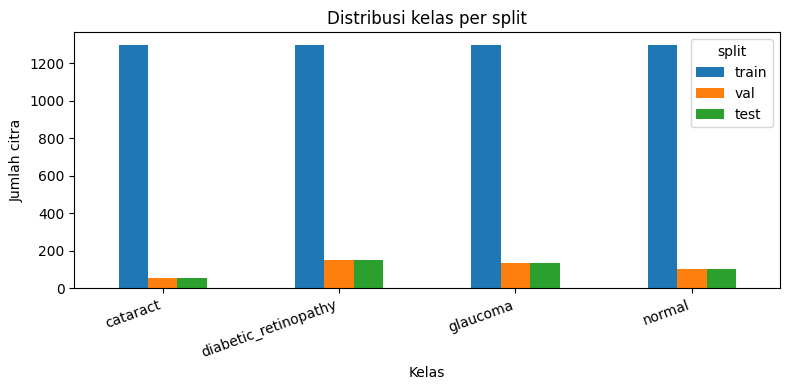

**Narasi Data Understanding.** Dataset yang berhasil diindeks berisi **6,086 file citra** dan **4 kelas** pada 3 split. Format yang terdeteksi: **JPEG (6078), PNG (8)**; dimensi unik: **224×224**; mode warna: **RGB**. Ditemukan **0 file tidak terbaca**. Jumlah missing values pada seluruh kolom metadata adalah **0**; rincian kolom yang memiliki nilai hilang: **tidak ada**. Tabel tipe data di atas menunjukkan tipe aktual setiap variabel, sehingga jenis data tidak hanya diasumsikan dari nama kolom. Distribusi kelas berbeda antar-split sebagaimana ditunjukkan tabel jumlah dan persentase; kondisi ini menjadi alasan penggunaan Macro F1 dan Balanced Accuracy. Hash MD5 juga digunakan untuk mengidentifikasi file identik sebelum pemodelan.

In [ ]:
def info_citra(path):
    """Audit satu citra; kegagalan baca dicatat tanpa menghentikan seluruh proses."""
    try:
        with open(path, "rb") as f:
            md5 = hashlib.md5(f.read()).hexdigest()
    except Exception:
        md5 = np.nan

    fmt, lebar, tinggi, mode = np.nan, np.nan, np.nan, np.nan
    try:
        with Image.open(path) as im:
            im.load()  # memastikan isi file dapat didekode, bukan hanya header
            fmt, (lebar, tinggi), mode = im.format, im.size, im.mode
        gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if gray is None:
            raise ValueError("OpenCV gagal membaca citra")
        status = "OK"
        black_ratio = float((gray < 10).mean())
        brightness = float(gray.mean())
        lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    except Exception as exc:
        status = f"TIDAK TERBACA: {type(exc).__name__}"
        black_ratio = brightness = lap_var = np.nan

    return {
        "format": fmt, "lebar": lebar, "tinggi": tinggi, "mode": mode,
        "ukuran_kb": os.path.getsize(path) / 1024 if os.path.exists(path) else np.nan,
        "md5": md5, "status_citra": status,
        "black_ratio": black_ratio, "brightness": brightness, "lap_var": lap_var,
    }

info = Parallel(n_jobs=N_JOBS)(delayed(info_citra)(p) for p in df["path"])
df = pd.concat([df.reset_index(drop=True), pd.DataFrame(info)], axis=1)
nama_file = df["path"].map(os.path.basename)
df["aug"] = nama_file.str.startswith("aug_")
df["aug_noise"] = nama_file.str.startswith("aug_noise_")

# Ringkasan kualitas umum
md5_valid = df.dropna(subset=["md5"]).groupby("md5")
kelompok_md5 = md5_valid.size()
ringkas_kualitas = pd.Series({
    "Jumlah observasi (file citra)": len(df),
    "Jumlah kelas": int(df["label"].nunique()),
    "Jumlah split": int(df["split"].nunique()),
    "Total missing values seluruh kolom": int(df.isna().sum().sum()),
    "Missing pada path/label/split": int(df[["path", "label", "split"]].isna().sum().sum()),
    "File tidak terbaca": int((df["status_citra"] != "OK").sum()),
    "Dimensi citra unik": ", ".join(sorted({f"{int(w)}x{int(h)}" for w, h in zip(df["lebar"].dropna(), df["tinggi"].dropna())})),
    "Mode warna unik": ", ".join(sorted(df["mode"].dropna().astype(str).unique())),
    "Format file": ", ".join(f"{k}={v}" for k, v in df["format"].value_counts(dropna=True).items()),
    "File bernama aug_*": int(df["aug"].sum()),
    "Di antaranya aug_noise_*": int(df["aug_noise"].sum()),
    "Kelompok MD5 duplikat": int((kelompok_md5 > 1).sum()),
    "Kelompok MD5 dengan label konflik": int((md5_valid["label"].nunique() > 1).sum()),
    "Kelompok MD5 yang muncul lintas split": int((md5_valid["split"].nunique() > 1).sum()),
}, name="Hasil aktual")
display(ringkas_kualitas.to_frame())

# Tipe data dan makna setiap variabel — tipe diambil langsung dari DataFrame.
keterangan_variabel = {
    "path": "Lokasi file citra pada penyimpanan.",
    "label": "Label kelas target dari nama folder.",
    "split": "Pembagian data bawaan: train, val, atau test.",
    "format": "Format berkas citra yang dibaca Pillow.",
    "lebar": "Lebar citra dalam piksel.",
    "tinggi": "Tinggi citra dalam piksel.",
    "mode": "Mode warna citra menurut Pillow (misalnya RGB).",
    "ukuran_kb": "Ukuran berkas dalam kilobyte.",
    "md5": "Hash isi berkas untuk mendeteksi duplikat identik.",
    "status_citra": "Status keberhasilan pembacaan citra.",
    "black_ratio": "Proporsi piksel grayscale dengan intensitas di bawah 10.",
    "brightness": "Rata-rata intensitas grayscale.",
    "lap_var": "Varians respons Laplacian; indikator aktivitas tepi/ketajaman, bukan bukti noise.",
    "aug": "Penanda nama file dengan awalan aug_.",
    "aug_noise": "Penanda nama file dengan awalan aug_noise_.",
}
tipe_variabel = pd.DataFrame({
    "Variabel": df.columns,
    "Tipe data aktual": [str(df[c].dtype) for c in df.columns],
    "Missing": [int(df[c].isna().sum()) for c in df.columns],
    "Nilai unik": [int(df[c].nunique(dropna=True)) for c in df.columns],
    "Keterangan": [keterangan_variabel.get(c, "Metadata hasil audit citra.") for c in df.columns],
}).set_index("Variabel")
display(tipe_variabel)

# Distribusi kelas: jumlah absolut dan persentase pada setiap split.
dist = pd.crosstab(df["split"], df["label"]).reindex(index=SPLITS, columns=LABEL_ORDER, fill_value=0)
dist_pct = dist.div(dist.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
print("Jumlah citra per kelas dan split:")
display(dist)
print("Persentase kelas di dalam masing-masing split (%):")
display(dist_pct.round(2))
dist.T.plot(kind="bar", figsize=(8, 4), title="Distribusi kelas per split")
plt.ylabel("Jumlah citra"); plt.xlabel("Kelas"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

# Narasi dibangun dari nilai aktual hasil pemeriksaan.
missing_cols = {c: int(v) for c, v in df.isna().sum().items() if v > 0}
formats = ", ".join(f"{k} ({v})" for k, v in df["format"].value_counts(dropna=True).items()) or "tidak teridentifikasi"
pasangan_dimensi = df[["lebar", "tinggi"]].dropna().drop_duplicates()
dims = sorted({f"{int(r.lebar)}×{int(r.tinggi)}" for r in pasangan_dimensi.itertuples()})
modes = sorted(df["mode"].dropna().astype(str).unique())
jumlah_tidak_terbaca = int((df["status_citra"] != "OK").sum())
display(Markdown(
    f"**Narasi Data Understanding.** Dataset yang berhasil diindeks berisi **{len(df):,} file citra** dan **{df['label'].nunique()} kelas** "
    f"pada {df['split'].nunique()} split. Format yang terdeteksi: **{formats}**; dimensi unik: **{', '.join(dims) if dims else 'tidak teridentifikasi'}**; "
    f"mode warna: **{', '.join(modes) if modes else 'tidak teridentifikasi'}**. Ditemukan **{jumlah_tidak_terbaca} file tidak terbaca**. "
    f"Jumlah missing values pada seluruh kolom metadata adalah **{int(df.isna().sum().sum())}**; "
    f"rincian kolom yang memiliki nilai hilang: **{missing_cols if missing_cols else 'tidak ada'}**. "
    f"Tabel tipe data di atas menunjukkan tipe aktual setiap variabel, sehingga jenis data tidak hanya diasumsikan dari nama kolom. "
    f"Distribusi kelas berbeda antar-split sebagaimana ditunjukkan tabel jumlah dan persentase; kondisi ini menjadi alasan penggunaan Macro F1 dan Balanced Accuracy. "
    f"Hash MD5 juga digunakan untuk mengidentifikasi file identik sebelum pemodelan."
))

**Interpretasi Data Understanding**

- **Kualitas berkas baik:** 6.086 citra RGB 224×224 (JPEG 6.078, PNG 8), tanpa missing value dan tanpa file rusak.
- **Distribusi kelas berbeda antar-split.** Train seimbang (1.300 per kelas), sedangkan val dan test timpang (cataract ≈12%, diabetic_retinopathy ≈34%, glaucoma ≈30%, normal ≈23%). Dummy mendapat Accuracy 0,343 tetapi Macro F1 hanya 0,128, sehingga Accuracy saja tidak mencerminkan performa per kelas. Karena itu Macro F1 dan Balanced Accuracy dijadikan metrik utama.
- **Ada data augmentasi:** 1.847 file berawalan `aug_`, termasuk 276 `aug_noise_*` yang seluruhnya berada di train (0 di val dan test).
- **Ada masalah label di sumber data:** dari 128 grup file identik (MD5), 125 grup berisi gambar yang sama dengan label berbeda, dan 3 grup muncul lintas split. Ini mengindikasikan label noise pada dataset sumber. Audit near-duplicate menemukan 61 citra train yang hampir identik dengan val/test, 45 di antaranya berlabel berbeda. Semuanya ditangani di bagian C, tetapi kualitas label tetap membatasi performa yang realistis.

## B.2 Exploratory Data Analysis (EDA)

EDA digunakan untuk melihat contoh citra pada setiap kelas, merangkum karakteristik visual melalui statistik deskriptif, dan mengamati perbedaan distribusi fitur citra. Audit `aug_noise_*` membandingkan penanda nama file dengan persentil tinggi `lap_var` pada data training.

**Batas interpretasi:** rasio piksel gelap, kecerahan, dan varians Laplacian adalah deskriptor citra, bukan diagnosis klinis. Varians Laplacian yang tinggi dapat muncul karena tepi/detail yang banyak maupun noise; karena itu hasilnya disebut aktivitas frekuensi tinggi/tepi, bukan bukti noise.

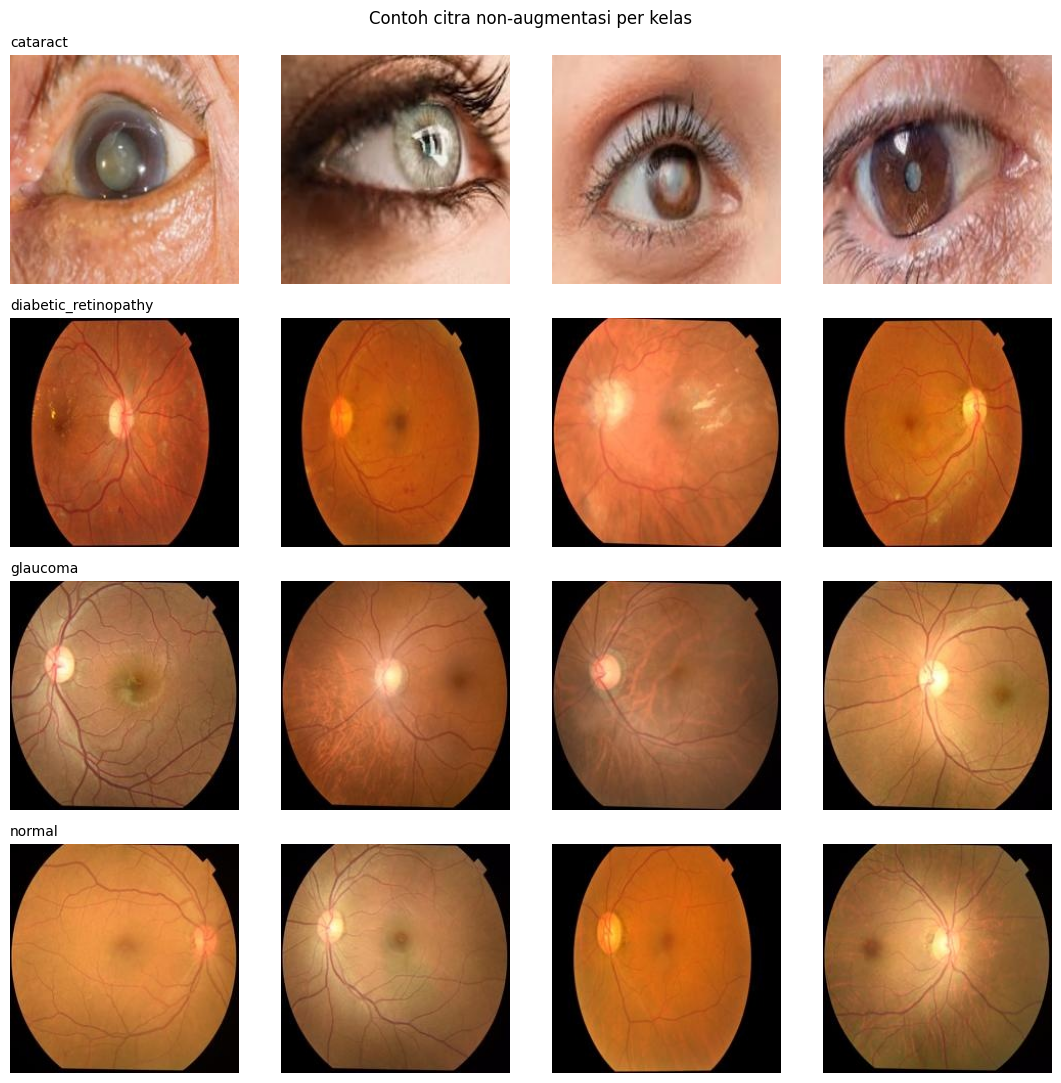

In [ ]:
# B.2a. Contoh citra tiap kelas (maksimal 4 contoh non-augmentasi per kelas)
fig, axes = plt.subplots(len(LABEL_ORDER), 4, figsize=(11, 11), squeeze=False)
for i, kelas in enumerate(LABEL_ORDER):
    subset = df[(df["label"] == kelas) & (~df["aug"]) & (df["status_citra"] == "OK")]
    n = min(4, len(subset))
    if n:
        contoh = subset.sample(n=n, random_state=RANDOM_STATE)
        for j, (_, row) in enumerate(contoh.iterrows()):
            axes[i, j].imshow(plt.imread(row["path"]))
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_title(kelas, loc="left", fontsize=10)
    else:
        axes[i, 0].text(0.5, 0.5, "Tidak ada contoh", ha="center", va="center")
        axes[i, 0].set_title(kelas, loc="left", fontsize=10)
    for j in range(n, 4):
        axes[i, j].axis("off")
plt.suptitle("Contoh citra non-augmentasi per kelas")
plt.tight_layout(); plt.show()

black_ratio                      brightness                           lap_var                              
                           count   mean median    std      count     mean   median     std   count      mean   median        std
label                                                                                                                           
cataract                    1409  0.017  0.000  0.043       1409  132.513  131.434  33.042    1409  4304.651  143.169  12822.758
diabetic_retinopathy        1602  0.221  0.157  0.088       1602   94.271   95.927  19.926    1602   563.421  197.535   3767.254
glaucoma                    1570  0.211  0.157  0.087       1570   96.655   99.635  19.348    1570  1157.145  211.898   6289.636
normal                      1505  0.173  0.156  0.073       1505  107.573  111.308  16.247    1505  2259.857  239.481   8906.584

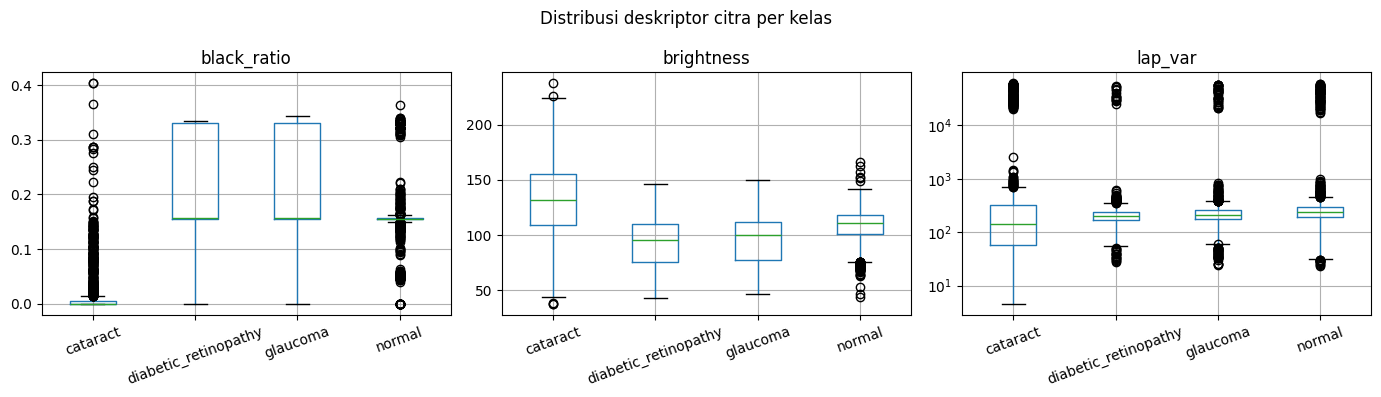

Rentang median antarkelas (deskriptif, bukan uji signifikansi):


,Rentang median antarkelas
black_ratio,0.157
brightness,35.507
lap_var,96.312


In [ ]:
# B.2b. Statistik deskriptif citra per kelas
stat_cols = ["black_ratio", "brightness", "lap_var"]
statistik_kelas = df.groupby("label")[stat_cols].agg(["count", "mean", "median", "std"]).round(3)
display(statistik_kelas)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, kolom in zip(axes, stat_cols):
    data_plot = df[["label", kolom]].dropna()
    if not data_plot.empty:
        data_plot.boxplot(column=kolom, by="label", ax=ax, rot=20)
    ax.set_title(kolom)
    ax.set_xlabel("")
    if kolom == "lap_var":
        ax.set_yscale("symlog", linthresh=1)
plt.suptitle("Distribusi deskriptor citra per kelas")
plt.tight_layout(); plt.show()

median_kelas = df.groupby("label")[stat_cols].median()
ringkasan_rentang = (median_kelas.max() - median_kelas.min()).rename("Rentang median antarkelas")
print("Rentang median antarkelas (deskriptif, bukan uji signifikansi):")
display(ringkasan_rentang.to_frame().round(3))

Ambang persentil 95% lap_var pada train: 22271.183
Jumlah file bernama aug_noise_*: 276
Jumlah citra pada/di atas ambang lap_var: 260
Tabel berikut menunjukkan apakah nama file aug_noise_* beririsan dengan kelompok lap_var tinggi:


lap_var >= P95 train,False,True
Nama file aug_noise_*,,
False,5810,0
True,16,260


aug_noise                   False  True 
label                split              
cataract             test      55      0
                     train   1156    144
                     val       54      0
diabetic_retinopathy test     152      0
                     train   1285     15
                     val      150      0
glaucoma             test     136      0
                     train   1263     37
                     val      134      0
normal               test     103      0
                     train   1220     80
                     val      102      0

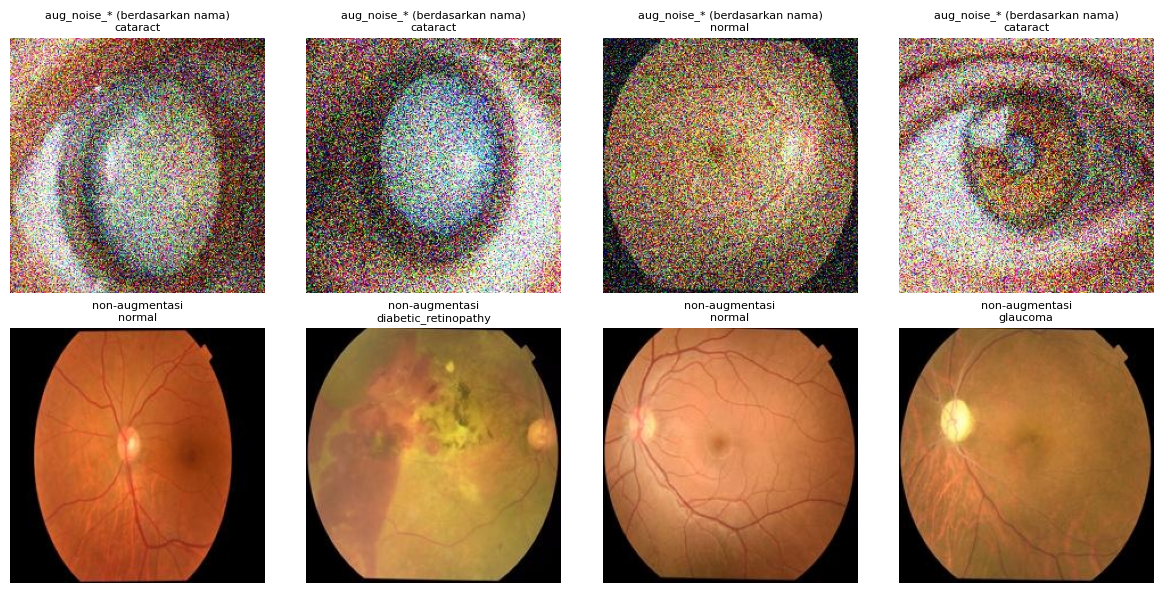

**Interpretasi audit `aug_noise`.** Dengan ambang persentil ke-95 data training sebesar **22271.183**, terdapat **260 citra** pada kelompok `lap_var` tinggi dan **276 file** dengan nama `aug_noise_*`. Crosstab memperlihatkan irisan kedua penanda tersebut. `aug_noise_*` adalah informasi dari nama file, sedangkan `lap_var_top5pct_train` adalah penanda statistik. Keduanya tidak boleh dianggap sebagai bukti bahwa suatu citra pasti mengandung noise. Dampak subset bernama `aug_noise_*` diuji secara empiris pada bagian E dan I.

In [ ]:
# B.2c. Audit aug_noise_* dibandingkan persentil tinggi varians Laplacian
# Ambang berasal dari persentil ke-95 data TRAIN; ini penanda statistik, bukan label noise.
nilai_lap_train = df.loc[df["split"] == "train", "lap_var"].dropna()
if nilai_lap_train.empty:
    raise ValueError("Tidak ada nilai lap_var valid pada data training; periksa kualitas citra.")
ambang_lap_var = float(nilai_lap_train.quantile(PERSENTIL_LAP_VAR))
df["lap_var_top5pct_train"] = df["lap_var"] >= ambang_lap_var
print(f"Ambang persentil {PERSENTIL_LAP_VAR:.0%} lap_var pada train: {ambang_lap_var:.3f}")
print("Jumlah file bernama aug_noise_*:", int(df["aug_noise"].sum()))
print("Jumlah citra pada/di atas ambang lap_var:", int(df["lap_var_top5pct_train"].sum()))
print("Tabel berikut menunjukkan apakah nama file aug_noise_* beririsan dengan kelompok lap_var tinggi:")
display(pd.crosstab(df["aug_noise"], df["lap_var_top5pct_train"],
                    rownames=["Nama file aug_noise_*"], colnames=["lap_var >= P95 train"]))
display(pd.crosstab([df["label"], df["split"]], df["aug_noise"]))

# Contoh visual dipilih dengan aman walaupun jumlah sampel kurang dari empat.
fig, axes = plt.subplots(2, 4, figsize=(12, 6), squeeze=False)
for baris_ax, (nama, subset) in zip(axes, [
    ("aug_noise_* (berdasarkan nama)", df[(df["aug_noise"]) & (df["status_citra"] == "OK")]),
    ("non-augmentasi", df[(~df["aug"]) & (df["status_citra"] == "OK")]),
]):
    n = min(4, len(subset))
    sampel = subset.sample(n=n, random_state=RANDOM_STATE) if n else subset
    for ax in baris_ax:
        ax.axis("off")
    for ax, (_, row) in zip(baris_ax, sampel.iterrows()):
        ax.imshow(plt.imread(row["path"]))
        ax.set_title(f"{nama}\n{row['label']}", fontsize=8)
        ax.axis("off")
    if n == 0:
        baris_ax[0].text(0.5, 0.5, "Tidak ada sampel", ha="center", va="center")
plt.tight_layout(); plt.show()

display(Markdown(
    f"**Interpretasi audit `aug_noise`.** Dengan ambang persentil ke-95 data training sebesar **{ambang_lap_var:.3f}**, "
    f"terdapat **{int(df['lap_var_top5pct_train'].sum())} citra** pada kelompok `lap_var` tinggi dan **{int(df['aug_noise'].sum())} file** "
    "dengan nama `aug_noise_*`. Crosstab memperlihatkan irisan kedua penanda tersebut. `aug_noise_*` adalah informasi dari nama file, "
    "sedangkan `lap_var_top5pct_train` adalah penanda statistik. Keduanya tidak boleh dianggap sebagai bukti bahwa suatu citra pasti mengandung noise. "
    "Dampak subset bernama `aug_noise_*` diuji secara empiris pada bagian E dan I."
))

**Temuan EDA**

1. **Cataract berasal dari jenis citra yang berbeda.** Contoh pada B.2a menunjukkan cataract berupa foto mata bagian luar, sedangkan diabetic_retinopathy, glaucoma, dan normal berupa citra fundus dengan latar hitam di tepi. Statistik mendukung ini: median `black_ratio` cataract 0,000 vs 0,156–0,157 pada kelas lain, dan median `brightness` 131,4 vs 95,9–111,3. Cataract mudah dipisahkan karena modalitas citranya, bukan pola penyakitnya (risiko *shortcut learning*). Implikasi: skor 4 kelas dilaporkan bersama skor 3 kelas fundus agar tidak dibaca sebagai kemampuan mendeteksi penyakit (bagian I.c).
2. **Tiga kelas fundus mirip pada deskriptor sederhana** (black_ratio, brightness), sehingga butuh fitur yang lebih kaya (HOG, tekstur). Implikasi: kesulitan memisahkan glaucoma dan normal sudah terlihat sejak EDA, dan memang menjadi kesalahan terbanyak model (glaucoma→normal 26 dan normal→glaucoma 18 pada validation, bagian I.a).
3. **`lap_var` sangat miring ke kanan** (cataract: mean 4.304 vs median 143), jadi mean/std kurang representatif dan fitur ini perlu ditangani (mis. transformasi log) pada UAS.
4. **Citra `aug_noise_*` memang ber-noise kuat** (terlihat pada B.2c). Seluruh 260 citra dengan `lap_var` ≥ P95 train adalah `aug_noise_*`, dan 0 dari 5.810 file lain berada di atas ambang itu. Sebanyak 144 dari 276 file `aug_noise_*` berlabel cataract. Implikasi: dampak `aug_noise_*` terhadap model perlu diuji (bagian E dan I.c), dan menghapusnya juga mengubah proporsi kelas pada train (cataract 1.290 → 1.146).
5. **Ada redundansi fitur:** 21 dari 496 pasangan fitur non-HOG memiliki |r| > 0,90 (mis. r_mean–v_mean 0,995). Fitur tidak dibuang pada UTS agar tidak ada seleksi di luar CV; ini dievaluasi pada UAS.

# C. Preprocessing

Preprocessing bertujuan mengaudit dan mengurangi duplikasi agar citra identik/hampir identik tidak tersebar pada split yang berbeda. Kebijakan yang digunakan:

| Tahap | Perlakuan | Alasan |
|---|---|---|
| C.a Duplikat identik (MD5) | Grup dengan label konflik dikeluarkan seluruhnya. Jika label sama, satu salinan dipertahankan dengan prioritas test, lalu validation, kemudian training. | Mencegah konflik label dan salinan identik lintas split. |
| C.b Near-duplicate (dHash + SSIM) | dHash digunakan untuk menyaring kandidat; SSIM digunakan untuk konfirmasi. Salinan train yang cocok dengan val/test dikeluarkan dari train; val yang cocok dengan test dikeluarkan dari val. | Mengurangi kebocoran akibat citra hampir sama. |
| C.c `aug_noise_*` | Tetap dipertahankan di training; dampaknya diuji dengan dua skenario. | Tidak menghapus data hanya berdasarkan dugaan visual/statistik. |
| C.d Persiapan model | Split bawaan dipertahankan. StandardScaler/PCA berada dalam Pipeline. | Transformasi dipelajari pada data latih/fold terkait. |

**Transparansi penggunaan test:** file pada split test tidak dihapus atau diubah. Namun, hash/kemiripan citra test **dipakai dalam audit lintas-split** untuk menemukan salinan yang perlu dikeluarkan dari training/validation. Karena itu, test bukan *blind test* yang sama sekali tidak pernah dilihat pada tahap kurasi. Keterbatasan ini harus dilaporkan. Untuk UAS, rancangan yang lebih kuat adalah membentuk ulang split berdasarkan grup sumber/pasien/keluarga augmentasi, tanpa memakai test untuk memilih keputusan model.

In [ ]:
# C.a. Keluarkan file tidak terbaca dan deduplikasi identik (MD5)
log_prep = []
def catat(tahap, d):
    hitung = d["split"].value_counts()
    log_prep.append({"Tahap": tahap, **{s: int(hitung.get(s, 0)) for s in SPLITS}, "Total": len(d)})

catat("C.a Data awal", df)
d_valid = df[df["status_citra"] == "OK"].copy()
print("File tidak terbaca yang dikeluarkan:", len(df) - len(d_valid))
catat("C.a Setelah keluarkan file tidak terbaca", d_valid)

prio = {"test": 0, "val": 1, "train": 2}  # untuk label sama: pertahankan test, lalu val, lalu train
d = d_valid.assign(_prioritas=d_valid["split"].map(prio)).sort_values(["_prioritas", "path"])
ada_hash = d["md5"].notna()
d_hash = d[ada_hash].copy()
d_tanpa_hash = d[~ada_hash].copy()  # tidak boleh dianggap saling duplikat hanya karena hash-nya hilang
konflik_hash = d_hash.groupby("md5")["label"].transform("nunique") > 1
jumlah_konflik = int(konflik_hash.sum())
d_hash_bersih = d_hash[~konflik_hash].drop_duplicates("md5")
d1 = (pd.concat([d_hash_bersih, d_tanpa_hash], axis=0)
      .drop(columns="_prioritas").sort_values("path").reset_index(drop=True))
print("Baris yang dikeluarkan karena grup MD5 memiliki label konflik:", jumlah_konflik)
print("Salinan identik tambahan yang dikeluarkan:", int((~konflik_hash).sum() - len(d_hash_bersih)))
print("File terbaca tetapi hash tidak tersedia (dipertahankan, tidak dideduplikasi):", len(d_tanpa_hash))
catat("C.a Setelah deduplikasi MD5", d1)

File tidak terbaca yang dikeluarkan: 0
Baris yang dikeluarkan karena grup MD5 memiliki label konflik: 250
Salinan identik tambahan yang dikeluarkan: 3
File terbaca tetapi hash tidak tersedia (dipertahankan, tidak dideduplikasi): 0


val/test -> train : kandidat dHash<=1 = 69 | terkonfirmasi SSIM>=0.98 = 61 (label berbeda: 45)
val -> test       : kandidat = 0 | terkonfirmasi = 0
Dikeluarkan dari train: 61 | dikeluarkan dari val: 0 | file test dipertahankan tanpa penghapusan.
Catatan: data test dipakai untuk mendeteksi kemiripan lintas-split pada tahap kurasi, sebagaimana dijelaskan di bagian C.


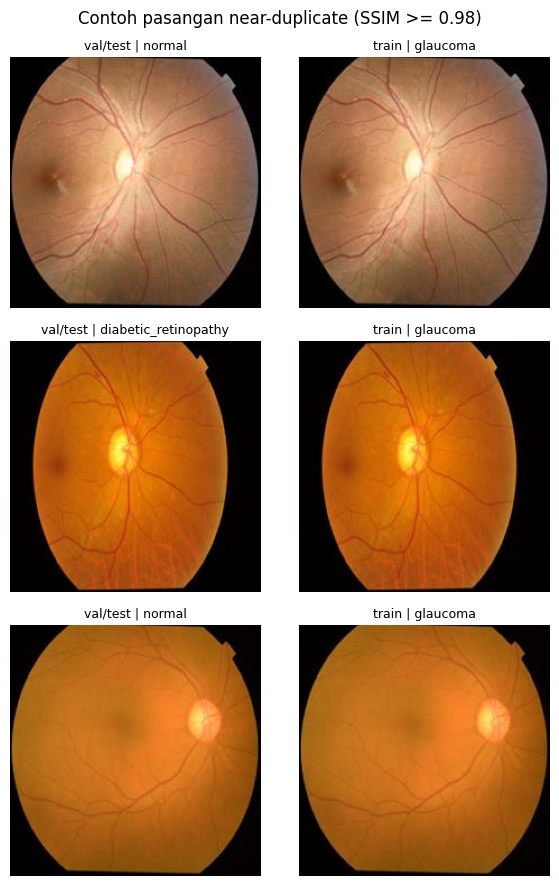

In [ ]:
# C.b. Near-duplicate lintas split: dHash (kandidat) + SSIM (konfirmasi)
from skimage.metrics import structural_similarity

def thumb_abu(path, n=17):
    with Image.open(path) as im:
        return np.asarray(im.convert("L").resize((n, n), Image.Resampling.BILINEAR), dtype=np.float32)

def dhash(t):                                   # 16x16 = 256 bit
    return (t[:16, 1:] > t[:16, :-1]).ravel().astype(np.float32)

def dhash_8_file(path):                         # 8 orientasi: {asli, flip} x rotasi 0/90/180/270
    with Image.open(path) as im:                # transformasi pada citra PENUH lalu di-resize (bukan pada thumbnail)
        g = np.asarray(im.convert("L"))
    out = []
    for flip in (False, True):
        a = np.fliplr(g) if flip else g
        for k in range(4):
            t = Image.fromarray(np.ascontiguousarray(np.rot90(a, k))).resize((17, 17), Image.Resampling.BILINEAR)
            out.append(dhash(np.asarray(t, dtype=np.float32)))
    return np.stack(out)

if d1.empty:
    raise ValueError("Tidak ada citra valid tersisa setelah pemeriksaan kualitas/MD5.")
thumbs = np.stack(Parallel(n_jobs=N_JOBS)(delayed(thumb_abu)(p) for p in d1["path"]))
H = np.stack([dhash(t) for t in thumbs])                    # (N, 256) orientasi asli (semua citra)
path_arr, label_arr, split_arr = d1["path"].to_numpy(), d1["label"].to_numpy(), d1["split"].to_numpy()

def cari_pasangan(idx_q, idx_t, dmax=DHASH_MAX, blok=200):
    if len(idx_q) == 0 or len(idx_t) == 0:
        return pd.DataFrame(columns=["q", "t", "dhash", "orient"])
    B = H[idx_t]; sb = B.sum(1); hasil = []
    for s in range(0, len(idx_q), blok):
        q = idx_q[s:s + blok]
        A = H8[q].reshape(-1, 256)
        jarak = np.rint(A.sum(1)[:, None] + sb[None, :] - 2 * (A @ B.T)).reshape(len(q), 8, len(idx_t))
        dmin, orient = jarak.min(1), jarak.argmin(1)
        for a, b in zip(*np.nonzero(dmin <= dmax)):
            hasil.append((int(q[a]), int(idx_t[b]), int(dmin[a, b]), int(orient[a, b])))
    return pd.DataFrame(hasil, columns=["q", "t", "dhash", "orient"])

def gray_penuh(i):
    with Image.open(path_arr[i]) as im:
        return np.asarray(im.convert("L"))

def ssim_area(q, t, o):
    """SSIM pada ukuran baku agar citra dengan dimensi berbeda tetap dapat dibandingkan."""
    a = gray_penuh(q)
    if o >= 4:
        a = np.fliplr(a)
    a = np.rot90(a, o % 4)
    b = gray_penuh(t)
    a = cv2.resize(a, (256, 256), interpolation=cv2.INTER_AREA)
    b = cv2.resize(b, (256, 256), interpolation=cv2.INTER_AREA)
    _, peta = structural_similarity(a, b, data_range=255, full=True)
    m = (a > 15) | (b > 15)  # fokus pada area non-latar gelap
    return float(peta[m].mean() if m.sum() >= 100 else peta.mean())

idx = {s: np.flatnonzero(split_arr == s) for s in SPLITS}
H8 = np.zeros((len(d1), 8, 256), dtype=np.float32)          # 8 orientasi, hanya untuk citra val/test (query)
idx_eval = np.concatenate([idx["val"], idx["test"]])
for i, h in zip(idx_eval, Parallel(n_jobs=N_JOBS)(delayed(dhash_8_file)(path_arr[i]) for i in idx_eval)):
    H8[i] = h
p_tr = cari_pasangan(idx_eval, idx["train"])   # val/test -> train
p_vt = cari_pasangan(idx["val"], idx["test"])                                    # val -> test
for p in (p_tr, p_vt):
    p["ssim"] = [ssim_area(q, t, o) for q, t, o in zip(p["q"], p["t"], p["orient"])]
    p["label_q"] = label_arr[p["q"].to_numpy(dtype=int)]
    p["label_t"] = label_arr[p["t"].to_numpy(dtype=int)]
    p["label_beda"] = p["label_q"] != p["label_t"]

ok_tr, ok_vt = p_tr[p_tr["ssim"] >= SSIM_MIN], p_vt[p_vt["ssim"] >= SSIM_MIN]
buang_train, buang_val = set(ok_tr["t"]), set(ok_vt["q"])
print(f"val/test -> train : kandidat dHash<={DHASH_MAX} = {len(p_tr)} | terkonfirmasi SSIM>={SSIM_MIN} = {len(ok_tr)} "
      f"(label berbeda: {int(ok_tr['label_beda'].sum())})")
print(f"val -> test       : kandidat = {len(p_vt)} | terkonfirmasi = {len(ok_vt)}")
print(f"Dikeluarkan dari train: {len(buang_train)} | dikeluarkan dari val: {len(buang_val)} | file test dipertahankan tanpa penghapusan.")
print("Catatan: data test dipakai untuk mendeteksi kemiripan lintas-split pada tahap kurasi, sebagaimana dijelaskan di bagian C.")

d2 = d1.drop(index=list(buang_train | buang_val)).reset_index(drop=True)
catat("C.b Setelah audit near-duplicate", d2)

# bukti visual: sampai 3 pasangan terkonfirmasi (label berbeda diprioritaskan)
tampil = ok_tr.sort_values("label_beda", ascending=False).head(3)
if len(tampil):
    fig, axes = plt.subplots(len(tampil), 2, figsize=(6, 3 * len(tampil)), squeeze=False)
    for ax_r, (_, r) in zip(axes, tampil.iterrows()):
        for ax, i, nm in zip(ax_r, (r["q"], r["t"]), ("val/test", "train")):
            ax.imshow(plt.imread(path_arr[int(i)])); ax.axis("off"); ax.set_title(f"{nm} | {label_arr[int(i)]}", fontsize=9)
    plt.suptitle(f"Contoh pasangan near-duplicate (SSIM >= {SSIM_MIN})"); plt.tight_layout(); plt.show()

In [ ]:
# C.c-C.d. Ringkasan perubahan jumlah citra setelah preprocessing
print("Jumlah citra per tahap dan split:")
display(pd.DataFrame(log_prep).set_index("Tahap"))
print("Distribusi label setelah preprocessing:")
display(pd.crosstab(d2["split"], d2["label"]).reindex(index=SPLITS, columns=LABEL_ORDER, fill_value=0))
print("File aug_noise_* yang tetap dipertahankan:", int(d2["aug_noise"].sum()))
print("Jumlah citra pada hasil preprocessing:", len(d2))

Jumlah citra per tahap dan split:


,train,val,test,Total
Tahap,,,,
C.a Data awal,5200,440,446,6086
C.a Setelah keluarkan file tidak terbaca,5200,440,446,6086
C.a Setelah deduplikasi MD5,4953,437,443,5833
C.b Setelah audit near-duplicate,4892,437,443,5772


Distribusi label setelah preprocessing:


label,cataract,diabetic_retinopathy,glaucoma,normal
split,,,,
train,1290,1292,1151,1159
val,54,150,132,101
test,55,151,135,102


File aug_noise_* yang tetap dipertahankan: 276
Jumlah citra pada hasil preprocessing: 5772


## C.1 Feature Engineering Awal

Setiap citra diubah menjadi **356 fitur numerik manual** dalam empat kelompok: warna (12), ketajaman/tepi (6), tekstur (14), dan HOG (324). Statistik warna dihitung dari kanal RGB/HSV; fitur ketajaman/tepi berasal dari grayscale dan kanal hijau dengan CLAHE; tekstur menggunakan LBP dan GLCM; HOG dihitung setelah citra grayscale diubah ke ukuran 64×64.

Fitur dihitung per citra. Matriks `X` berisi kolom fitur numerik dan vektor `y` berisi label. Pemeriksaan boxplot/korelasi dilakukan pada train sebagai EDA. Pemilihan kelompok fitur awal dilakukan dengan Stratified 5-Fold CV di dalam data train; tidak ada penghapusan fitur berbasis korelasi yang dihitung dari seluruh train sebelum CV, sehingga fold validasi internal tidak ikut memengaruhi penyaringan fitur. Validation kemudian dipakai untuk membandingkan konfigurasi model pada bagian E.

In [ ]:
# C.1a. Ekstraksi 356 fitur numerik manual
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, hog

def _mask(gray):
    mask = gray > 15
    if mask.sum() < 100:
        mask[:] = True
    return mask

def fitur_warna(path):
    with Image.open(path) as source:
        img = source.convert("RGB")
    rgb = np.asarray(img, dtype=float)
    hsv = np.asarray(img.convert("HSV"), dtype=float)
    mask = _mask(np.asarray(img.convert("L")))
    kanal = zip("rgbhsv", [rgb[..., 0], rgb[..., 1], rgb[..., 2], hsv[..., 0], hsv[..., 1], hsv[..., 2]])
    return {f"{nama}_{stat}": getattr(ch[mask], stat)()
            for nama, ch in kanal for stat in ("mean", "std")}

def fitur_ketajaman(path):
    bgr = cv2.imread(path)
    if bgr is None:
        raise ValueError(f"Citra tidak terbaca saat ekstraksi fitur: {path}")
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    mask = _mask(gray)
    bagian_dalam = cv2.erode(mask.astype(np.uint8), np.ones((7, 7), np.uint8)).astype(bool)
    if bagian_dalam.sum() < 100:
        bagian_dalam = mask
    green_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(bgr[:, :, 1])
    return {
        "lap_var": cv2.Laplacian(gray, cv2.CV_64F)[bagian_dalam].var(),
        "edge_density": (cv2.Canny(gray, 50, 150)[bagian_dalam] > 0).mean(),
        "g_clahe_mean": green_clahe[mask].mean(),
        "g_clahe_std": green_clahe[mask].std(),
        "dark_ratio": (green_clahe[mask] < 60).mean(),
        "bright_ratio": (green_clahe[mask] > 200).mean(),
    }

def fitur_tekstur(path):
    with Image.open(path) as source:
        gray = np.asarray(source.convert("L"))
    mask = _mask(gray)
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    hist = np.histogram(lbp[mask], bins=10, range=(0, 10))[0].astype(float)
    hist = hist / max(hist.sum(), 1.0)
    fitur = {f"lbp_{j}": nilai for j, nilai in enumerate(hist)}

    # Ambil 50% area tengah secara proporsional, tidak mengasumsikan ukuran citra 224x224.
    tinggi, lebar = gray.shape
    y0, y1 = int(0.25 * tinggi), max(int(0.75 * tinggi), int(0.25 * tinggi) + 1)
    x0, x1 = int(0.25 * lebar), max(int(0.75 * lebar), int(0.25 * lebar) + 1)
    tengah = gray[y0:y1, x0:x1]
    tengah = np.asarray(Image.fromarray(tengah).resize((112, 112), Image.Resampling.BILINEAR))
    tengah_32 = (tengah // 8).astype(np.uint8)
    glcm = graycomatrix(tengah_32, distances=[1, 3], angles=[0, np.pi / 2],
                        levels=32, symmetric=True, normed=True)
    fitur.update({f"glcm_{p}": graycoprops(glcm, p).mean()
                  for p in ("contrast", "homogeneity", "energy", "correlation")})
    return fitur

def fitur_hog(path):
    with Image.open(path) as source:
        gray = source.convert("L")
        kecil = np.asarray(gray.resize((64, 64), Image.Resampling.BILINEAR))
    values = hog(kecil, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    return {f"hog_{j}": nilai for j, nilai in enumerate(values)}

def ekstrak(path):
    hasil = {}
    for fungsi in (fitur_warna, fitur_ketajaman, fitur_tekstur, fitur_hog):
        hasil.update(fungsi(path))
    return hasil

GRUP = {
    "warna": [f"{n}_{s}" for n in "rgbhsv" for s in ("mean", "std")],
    "ketajaman": ["lap_var", "edge_density", "g_clahe_mean", "g_clahe_std", "dark_ratio", "bright_ratio"],
    "tekstur": [f"lbp_{i}" for i in range(10)] +
               [f"glcm_{p}" for p in ("contrast", "homogeneity", "energy", "correlation")],
    "hog": [f"hog_{i}" for i in range(324)],
}
SEMUA = [kolom for grup in GRUP.values() for kolom in grup]
NON_HOG = SEMUA[:-324]
assert len(SEMUA) == 356 and len(set(SEMUA)) == 356

F = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(ekstrak)(p) for p in d2["path"]))
assert set(F.columns) == set(SEMUA) and len(F) == len(d2)
data = pd.concat([
    d2[["path", "label", "split", "aug_noise"]].reset_index(drop=True),
    F[SEMUA].reset_index(drop=True)
], axis=1)

nilai_fitur = data[SEMUA].to_numpy(dtype=float)
print("Dimensi data fitur:", data.shape)
print("Missing pada fitur:", int(data[SEMUA].isna().sum().sum()))
print("Nilai inf pada fitur:", int(np.isinf(nilai_fitur).sum()))
if data[SEMUA].isna().any().any() or not np.isfinite(nilai_fitur).all():
    raise ValueError("Ekstraksi fitur menghasilkan NaN/inf. Periksa file citra dan fungsi ekstraksi sebelum pemodelan.")
data.to_csv("fitur_mata_model.csv", index=False)

# Pembentukan X (356 prediktor) dan y (target kelas) untuk seluruh citra.
X = data[SEMUA].copy()
y = data["label"].copy()
print("Dimensi X:", X.shape, "| dimensi y:", y.shape)
display(pd.DataFrame({
    "Jumlah fitur": [len(GRUP[g]) for g in GRUP],
    "Deskripsi": [
        "Mean dan standar deviasi kanal RGB dan HSV",
        "Varians Laplacian, kepadatan tepi Canny, statistik kanal hijau+CLAHE",
        "Histogram LBP dan empat properti GLCM",
        "Histogram of Oriented Gradients pada citra 64x64",
    ],
    "Rasional awal": [
        "Meringkas distribusi warna dan intensitas citra",
        "Meringkas aktivitas tepi, ketajaman, dan kontras lokal",
        "Meringkas pola tekstur grayscale",
        "Meringkas orientasi gradien/tepi",
    ],
}, index=list(GRUP)).rename_axis("Kelompok fitur"))

Dimensi data fitur: (5772, 360)
Missing pada fitur: 0
Nilai inf pada fitur: 0
Dimensi X: (5772, 356) | dimensi y: (5772,)


,Jumlah fitur,Deskripsi,Rasional awal
Kelompok fitur,,,
warna,12,Mean dan standar deviasi kanal RGB dan HSV,Meringkas distribusi warna dan intensitas citra
ketajaman,6,"Varians Laplacian, kepadatan tepi Canny, stati...","Meringkas aktivitas tepi, ketajaman, dan kontr..."
tekstur,14,Histogram LBP dan empat properti GLCM,Meringkas pola tekstur grayscale
hog,324,Histogram of Oriented Gradients pada citra 64x64,Meringkas orientasi gradien/tepi


lap_var                      edge_density               glcm_contrast                   b_mean                    s_mean                  g_clahe_mean                 
                       median      mean        std       median   mean    std        median    mean     std   median     mean     std   median     mean     std       median     mean     std
label                                                                                                                                                                                        
cataract              111.619  4609.432  13115.412        0.078  0.116  0.104         3.184  10.381  20.488  112.667  113.485  29.259   87.384   87.385  23.912      133.823  135.721  21.269
diabetic_retinopathy   50.696   511.250   4282.439        0.016  0.026  0.045         0.561   1.348   6.573   33.442   37.184  20.690  208.607  202.931  29.548      116.083  116.135  16.034
glaucoma               75.020  1416.826   7572.265        0.039  0.051  0.065         0.823   3.005  11.728   57.641   55.412  22.152  171.253  173.347  34.579      119.033  118.837  14.488
normal                 89.801  2843.103  10444.843        0.050  0.074  0.087         0.884   5.182  15.944   67.339   65.159  20.037  160.713  163.053  30.739      129.897  128.017  11.917

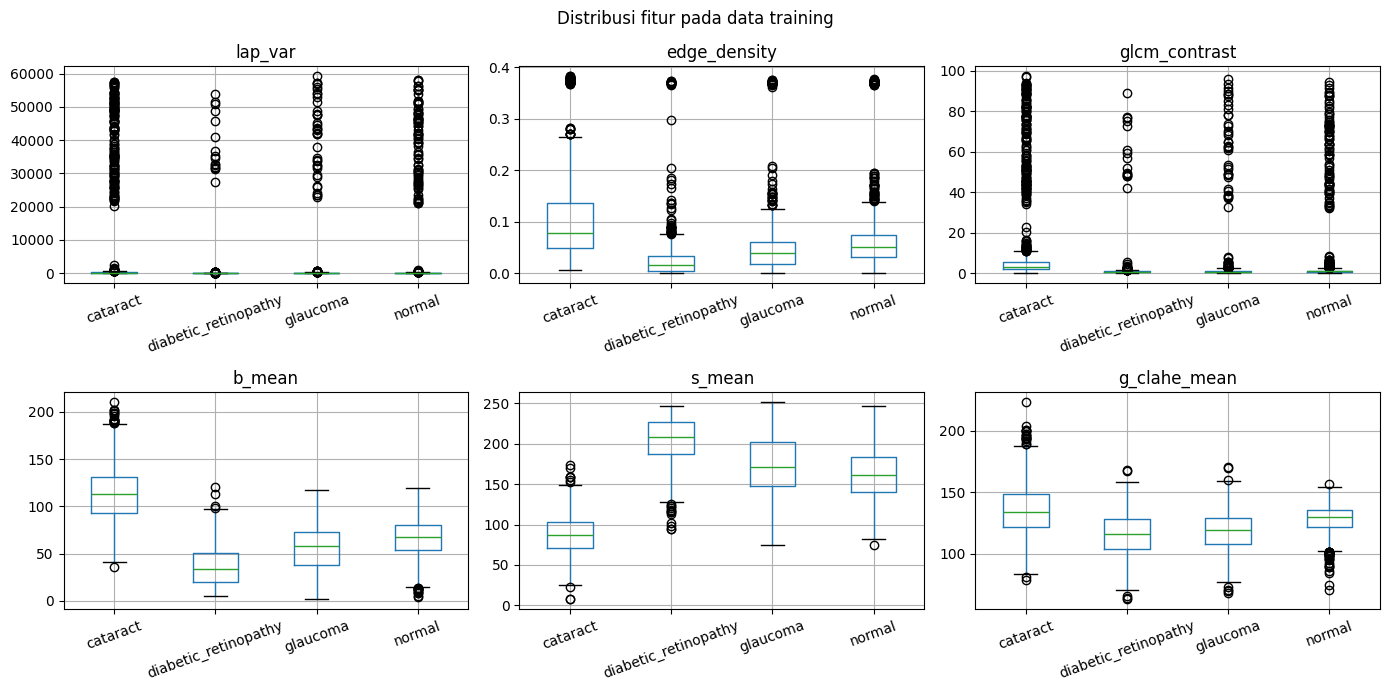

Pasangan fitur non-HOG dengan |r| > 0.90: 21 dari 496 pasangan.


Korelasi absolut
r_mean  v_mean                       0.995
r_std   v_std                        0.994
lap_var glcm_contrast                0.990
g_mean  g_clahe_mean                 0.971
lbp_0   lbp_9                        0.966
g_std   b_std                        0.957
lbp_0   glcm_correlation             0.953
g_std   g_clahe_std                  0.952
lbp_1   lbp_9                        0.942
        lbp_5                        0.941

In [ ]:
# C.1b. EDA fitur numerik (hanya TRAIN)
tr = data[data["split"] == "train"].copy()
kunci = ["lap_var", "edge_density", "glcm_contrast", "b_mean", "s_mean", "g_clahe_mean"]
missing_kunci = sorted(set(kunci) - set(data.columns))
if missing_kunci:
    raise KeyError(f"Fitur untuk EDA tidak ditemukan: {missing_kunci}")
display(tr.groupby("label")[kunci].agg(["median", "mean", "std"]).round(3))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, kolom in zip(axes.ravel(), kunci):
    tr.boxplot(column=kolom, by="label", ax=ax, rot=20)
    ax.set_title(kolom); ax.set_xlabel("")
plt.suptitle("Distribusi fitur pada data training")
plt.tight_layout(); plt.show()

NON_HOG = [c for c in SEMUA if not c.startswith("hog_")]
kor = tr[NON_HOG].corr().abs()
pasangan = (kor.where(np.triu(np.ones(kor.shape, dtype=bool), k=1))
            .stack().sort_values(ascending=False))
print(f"Pasangan fitur non-HOG dengan |r| > 0.90: {int((pasangan > 0.90).sum())} dari {len(pasangan)} pasangan.")
display(pasangan.head(10).round(3).to_frame("Korelasi absolut"))

In [ ]:
# C.1c. Seleksi kelompok fitur awal dengan CV pada TRAIN saja
# Validation dan test tidak dipakai untuk memilih kelompok fitur.
y_tr = tr["label"].copy()
jumlah_min_per_kelas = int(y_tr.value_counts().min())
if jumlah_min_per_kelas < N_SPLITS:
    raise ValueError(
        f"Stratified {N_SPLITS}-Fold CV membutuhkan minimal {N_SPLITS} sampel per kelas; "
        f"kelas terkecil hanya memiliki {jumlah_min_per_kelas}. Sesuaikan N_SPLITS secara metodologis."
    )

SET_FITUR = {
    "Warna (12)": GRUP["warna"],
    "Ketajaman (6)": GRUP["ketajaman"],
    "Tekstur (14)": GRUP["tekstur"],
    "HOG (324)": GRUP["hog"],
    "Non-HOG (32)": NON_HOG,
    "Semua (356)": SEMUA,
}
baris_fe = []
for nama, kolom_fitur in SET_FITUR.items():
    hasil_cv = cross_validate(
        buat_model("SVM RBF", 1.0, y_tr), tr[kolom_fitur], y_tr,
        cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
    )
    baris_fe.append({
        "Set fitur": nama,
        "Jumlah fitur": len(kolom_fitur),
        "CV Macro F1 mean": hasil_cv["test_f1"].mean(),
        "CV Macro F1 std": hasil_cv["test_f1"].std(ddof=1),
        "CV Balanced Acc mean": hasil_cv["test_ba"].mean(),
        "CV Accuracy mean": hasil_cv["test_acc"].mean(),
    })
tabel_fe = pd.DataFrame(baris_fe).set_index("Set fitur")
display(tabel_fe.round(4))

# Aturan diprapilih: subset alternatif harus unggul > 0.01 CV Macro F1 dibanding semua fitur.
skor = tabel_fe["CV Macro F1 mean"]
kandidat_fe = skor.idxmax()
if kandidat_fe != "Semua (356)" and skor[kandidat_fe] - skor["Semua (356)"] > 0.01:
    FITUR_MODEL = SET_FITUR[kandidat_fe]
    alasan_fitur = f"{kandidat_fe} unggul lebih dari 0,01 CV Macro F1 terhadap semua fitur."
else:
    FITUR_MODEL = SEMUA
    alasan_fitur = "Tidak ada subset yang unggul lebih dari 0,01; seluruh 356 fitur dipertahankan."
print(f"Set fitur terpilih: {len(FITUR_MODEL)} fitur. {alasan_fitur}")

# Validation/test baru dipakai setelah pemilihan fitur selesai.
va = data[data["split"] == "val"].copy()
te = data[data["split"] == "test"].copy()
y_va, y_te = va["label"].copy(), te["label"].copy()
X_va, X_te = va[FITUR_MODEL], te[FITUR_MODEL]
print("Ukuran train/validation/test:", len(tr), len(va), len(te))

,Jumlah fitur,CV Macro F1 mean,CV Macro F1 std,CV Balanced Acc mean,CV Accuracy mean
Set fitur,,,,,
Warna (12),12,0.6987,0.0159,0.7045,0.7138
Ketajaman (6),6,0.6404,0.0110,0.6499,0.6596
Tekstur (14),14,0.7194,0.0105,0.7279,0.7359
HOG (324),324,0.7948,0.0193,0.7960,0.8013
Non-HOG (32),32,0.7969,0.0160,0.7989,0.8062
Semua (356),356,0.8206,0.0154,0.8219,0.8275


Set fitur terpilih: 356 fitur. Tidak ada subset yang unggul lebih dari 0,01; seluruh 356 fitur dipertahankan.
Ukuran train/validation/test: 4892 437 443


**Interpretasi Feature Engineering Awal**

- C.1a membentuk 356 prediktor numerik dari empat kelompok fitur dan membentuk `X` serta `y` secara eksplisit.
- C.1b menampilkan distribusi fitur pada data training saja; korelasi hanya dilaporkan secara deskriptif dan tidak dipakai sebagai filter global sebelum CV.
- C.1c membandingkan kelompok fitur menggunakan Stratified 5-Fold CV pada training. Aturan pemilihan subset menggunakan ambang peningkatan CV Macro F1 lebih dari 0,01 dibandingkan seluruh fitur.
- CV pada C.1c berfungsi untuk seleksi fitur awal. Karena subset dipilih dari hasil CV yang sama, skor tertinggi pada tabel tersebut bukan estimasi final yang bebas bias. Performa model tetap dibandingkan pada validation di bagian D–H.

# D. Baseline

Dua baseline digunakan sebagai pembanding awal. Keduanya dilatih menggunakan data training dengan fitur terpilih pada bagian C.1.

- **Dummy (majority class):** selalu memprediksi kelas terbanyak dan berfungsi sebagai batas bawah performa.
- **Logistic Regression:** model linear sederhana yang distandardisasi; digunakan untuk menilai apakah model yang lebih kompleks memberikan peningkatan berarti.

Baseline dihitung pada validation terlebih dahulu. Nilai test baru dihitung pada bagian H setelah model final dipilih.


In [ ]:
SKENARIO = ["Dengan aug_noise", "Tanpa aug_noise"]
def latih(skenario):
    sub = tr if skenario == "Dengan aug_noise" else tr[~tr["aug_noise"]]
    kelas_hilang = sorted(set(LABEL_ORDER) - set(sub["label"].unique()))
    if kelas_hilang:
        raise ValueError(f"Skenario {skenario} kehilangan kelas training: {kelas_hilang}")
    return sub[FITUR_MODEL], sub["label"]

X_va, X_te = va[FITUR_MODEL], te[FITUR_MODEL]
print("Jumlah fitur model:", len(FITUR_MODEL), "| train/val/test:", len(tr), len(va), len(te))

hasil_val = []     # satu baris per model yang dilaporkan (metrik di validation)
X_l, y_l = latih("Dengan aug_noise")
for tahap, nama, nilai, konf in [("Baseline", "Dummy", "-", "majority class"),
                                 ("Baseline", "Logistic Regression", 1.0, "C=1.0")]:
    m = buat_model(nama, nilai, y_l).fit(X_l, y_l)
    hasil_val.append({"Tahap": tahap, "Model": nama, "Konfigurasi": konf, "Nilai": nilai,
                      "Data latih": "Dengan aug_noise", **metrik(y_va, m.predict(X_va))})

# ===== TAMBAHAN: baseline Logistic Regression dengan data latih yang sama seperti model final =====
X_t, y_t = latih("Tanpa aug_noise")
m = buat_model("Logistic Regression", 1.0, y_t).fit(X_t, y_t)
hasil_val.append({"Tahap": "Baseline", "Model": "Logistic Regression", "Konfigurasi": "C=1.0",
                  "Nilai": 1.0, "Data latih": "Tanpa aug_noise", **metrik(y_va, m.predict(X_va))})
# ===== AKHIR TAMBAHAN =====

display(pd.DataFrame(hasil_val).drop(columns="Nilai").round(4))

Jumlah fitur model: 356 | train/val/test: 4892 437 443


,Tahap,Model,Konfigurasi,Data latih,Accuracy,Balanced Acc,Macro F1
0,Baseline,Dummy,majority class,Dengan aug_noise,0.3432,0.2500,0.1278
1,Baseline,Logistic Regression,C=1.0,Dengan aug_noise,0.8124,0.8374,0.8352
2,Baseline,Logistic Regression,C=1.0,Tanpa aug_noise,0.8124,0.8374,0.8353


# E. Kandidat Model Awal

Enam algoritma *Classical Machine Learning* diuji karena mewakili karakteristik model yang berbeda.

| Model | Alasan pemilihan |
|---|---|
| SVM RBF | Batas keputusan non-linear pada fitur numerik yang distandardisasi. |
| Extra Trees | Ensemble pohon acak; mampu memodelkan hubungan non-linear dan tidak memerlukan scaling. |
| LDA (shrinkage) | Model linear dengan regularisasi kovarians. |
| QDA (+PCA) | Batas keputusan kuadratik; PCA mengurangi dimensi sebelum estimasi kovarians. |
| Ridge Classifier | Model linear dengan regularisasi L2. |
| Passive-Aggressive | Model linear berbasis margin; disertakan sebagai kandidat konvensional. |

Setiap algoritma diuji pada grid hyperparameter kecil dan dua skenario data training: dengan/tanpa citra bernama `aug_noise_*`. Konfigurasi terbaik per keluarga model dipilih berdasarkan Macro F1 validation. **Karena banyak konfigurasi dibandingkan pada validation yang sama, skor validation bersifat selektif dan dapat optimistik.** Oleh sebab itu, hasil validation dipakai untuk pemilihan model awal, bukan diklaim sebagai estimasi generalisasi yang sepenuhnya bebas bias.

In [ ]:
GRID = [
    ("SVM RBF", "C", [1.0, 10.0, 100.0]),
    ("Extra Trees", "max_features", ["sqrt", 0.3]),
    ("LDA", "shrinkage", ["auto", 0.2]),
    ("QDA", "reg_param", [0.1, 0.5, 0.8]),
    ("Ridge Classifier", "alpha", [0.1, 10.0, 100.0]),
    ("Passive-Aggressive", "C", [0.001, 0.01, 0.1]),
]

baris = []
for skenario in SKENARIO:
    X_l, y_l = latih(skenario)
    for nama, nama_param, daftar_nilai in GRID:
        for nilai in daftar_nilai:
            model = buat_model(nama, nilai, y_l).fit(X_l, y_l)
            baris.append({
                "Model": nama,
                "Konfigurasi": f"{nama_param}={nilai}",
                "Nilai": nilai,
                "Data latih": skenario,
                "n_latih": len(X_l),
                **metrik(y_va, model.predict(X_va)),
            })

tabel_grid = pd.DataFrame(baris)
tabel_grid.drop(columns="Nilai").to_csv("catatan_eksperimen_tuning.csv", index=False)
print("Jumlah konfigurasi yang dievaluasi:", len(tabel_grid))

urut = ["Macro F1", "Balanced Acc"]
terbaik_model = (
    tabel_grid.sort_values(urut, ascending=False)
    .groupby("Model", sort=False).head(1)
    .sort_values(urut, ascending=False).reset_index(drop=True)
)
display(terbaik_model.drop(columns="Nilai").round(4))

for _, r in terbaik_model.iterrows():
    hasil_val.append({
        "Tahap": "Kandidat", "Model": r["Model"], "Konfigurasi": r["Konfigurasi"],
        "Nilai": r["Nilai"], "Data latih": r["Data latih"],
        "Accuracy": r["Accuracy"], "Balanced Acc": r["Balanced Acc"], "Macro F1": r["Macro F1"],
    })

Jumlah konfigurasi yang dievaluasi: 32


,Model,Konfigurasi,Data latih,n_latih,Accuracy,Balanced Acc,Macro F1
0,SVM RBF,C=10.0,Tanpa aug_noise,4616,0.8284,0.8495,0.8475
1,Passive-Aggressive,C=0.01,Tanpa aug_noise,4616,0.8009,0.8249,0.8243
2,Extra Trees,max_features=0.3,Tanpa aug_noise,4616,0.8032,0.8276,0.8218
3,LDA,shrinkage=auto,Tanpa aug_noise,4616,0.7918,0.8209,0.8188
4,Ridge Classifier,alpha=100.0,Tanpa aug_noise,4616,0.7872,0.8184,0.8140
5,QDA,reg_param=0.5,Tanpa aug_noise,4616,0.7162,0.7603,0.7570


# F. Strategi Evaluasi

| Aspek | Keputusan | Alasan |
|---|---|---|
| Pembagian data | Split bawaan dataset: **train / val / test**, setelah audit duplikasi. | Mempertahankan pembagian sumber sambil mengurangi salinan lintas-split. |
| Pemilihan fitur awal | Stratified 5-Fold CV pada train di bagian C.1c. | Validation tidak dipakai untuk memilih subset fitur. |
| Pemilihan konfigurasi/model | Hold-out validation; Macro F1 menjadi metrik utama. | Memilih model kandidat dengan perhatian setara pada tiap kelas. |
| Uji kestabilan | Stratified 5-Fold CV pada train untuk baseline dan konfigurasi kandidat terpilih. | Menunjukkan variasi antar-fold, bukan estimasi independen bebas bias. |
| Evaluasi akhir | Test dipakai pada tahap H setelah kandidat final dipilih dari validation. | Test tidak digunakan untuk memilih hyperparameter atau model. Prediksi yang dibuat pada tahap H disimpan dan dipakai ulang pada analisis. |
| Metrik | Macro F1 utama; Balanced Accuracy, Accuracy, precision/recall/F1 per kelas sebagai pendukung. | Menilai kualitas klasifikasi pada distribusi kelas yang mungkin tidak seimbang. |
| Pencegahan leakage | Audit MD5/dHash+SSIM; scaling dan PCA di Pipeline. | Mengurangi kemiripan lintas-split dan memastikan transformasi dipelajari dari data latih/fold. |

**Batas interpretasi CV:** hyperparameter kandidat dipilih menggunakan validation, sedangkan CV dihitung untuk konfigurasi yang telah dipilih. Karena itu, CV di bagian F adalah indikator kestabilan relatif pada training, bukan pengganti nested cross-validation dan bukan estimasi yang sepenuhnya bebas bias seleksi. Split bawaan juga belum tentu memisahkan pasien/sumber citra; hal ini menjadi rencana perbaikan UAS.

In [ ]:
# F. Ringkasan distribusi split dan stabilitas CV pada data training
# Objek cv dan scoring telah didefinisikan pada bagian Setup agar konsisten di C.1c dan F.
display(pd.DataFrame({
    "Train": y_tr.value_counts(),
    "Train (tanpa aug_noise)": latih("Tanpa aug_noise")[1].value_counts(),
    "Validation": y_va.value_counts(),
    "Test": y_te.value_counts(),
}).reindex(LABEL_ORDER).fillna(0).astype(int))

hasil_cv = []
for r in hasil_val:
    X_l, y_l = latih(r["Data latih"])
    skor_cv = cross_validate(
        buat_model(r["Model"], r["Nilai"], y_l), X_l, y_l,
        cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
    )
    r.update({
        "CV Macro F1 (mean)": skor_cv["test_f1"].mean(),
        "CV Macro F1 (std)": skor_cv["test_f1"].std(ddof=1),
        "CV Balanced Acc (mean)": skor_cv["test_ba"].mean(),
        "CV Accuracy (mean)": skor_cv["test_acc"].mean(),
    })
    hasil_cv.append(r)

display(pd.DataFrame(hasil_cv)[[
    "Tahap", "Model", "Konfigurasi", "Data latih", "CV Macro F1 (mean)", "CV Macro F1 (std)",
    "CV Balanced Acc (mean)", "CV Accuracy (mean)"
]].round(4))

,Train,Train (tanpa aug_noise),Validation,Test
label,,,,
cataract,1290,1146,54,55
diabetic_retinopathy,1292,1277,150,151
glaucoma,1151,1114,132,135
normal,1159,1079,101,102


,Tahap,Model,Konfigurasi,Data latih,CV Macro F1 (mean),CV Macro F1 (std),CV Balanced Acc (mean),CV Accuracy (mean)
0,Baseline,Dummy,majority class,Dengan aug_noise,0.1045,0.0001,0.2500,0.2641
1,Baseline,Logistic Regression,C=1.0,Dengan aug_noise,0.8212,0.0130,0.8214,0.8264
2,Baseline,Logistic Regression,C=1.0,Tanpa aug_noise,0.8299,0.0211,0.8301,0.8321
3,Kandidat,SVM RBF,C=10.0,Tanpa aug_noise,0.8497,0.0206,0.8501,0.8520
4,Kandidat,Passive-Aggressive,C=0.01,Tanpa aug_noise,0.7946,0.0107,0.7949,0.7979
5,Kandidat,Extra Trees,max_features=0.3,Tanpa aug_noise,0.8292,0.0087,0.8309,0.8349
6,Kandidat,LDA,shrinkage=auto,Tanpa aug_noise,0.8159,0.0189,0.8168,0.8187
7,Kandidat,Ridge Classifier,alpha=100.0,Tanpa aug_noise,0.8160,0.0187,0.8178,0.8204
8,Kandidat,QDA,reg_param=0.5,Tanpa aug_noise,0.7552,0.0082,0.7573,0.7574


# G. Ensemble: Perbandingan dengan Model Awal

Ensemble yang diuji pada Milestone 1 adalah **hard voting**. Tiga keluarga model tunggal dengan Macro F1 validation tertinggi dipilih dari skenario data training yang sama (`Dengan aug_noise` atau `Tanpa aug_noise`). Setiap anggota memberikan satu suara kelas; prediksi akhir adalah kelas dengan suara terbanyak.

Ensemble dibandingkan dengan baseline dan kandidat tunggal pada validation. CV training digunakan untuk melihat variasi antar-fold. Karena anggota ensemble dipilih berdasarkan validation, skor validation ensemble juga termasuk hasil seleksi dan dapat optimistik. Test tetap tidak digunakan untuk memilih anggota ensemble.

In [ ]:
# G. Hard Voting: tiga model tunggal berbeda pada skenario training yang sama
rata_skenario = (
    tabel_grid.groupby(["Data latih", "Model"])["Macro F1"].max()
    .groupby("Data latih").mean().sort_values(ascending=False)
)
SKENARIO_ENSEMBLE = rata_skenario.index[0]

top_ensemble = (
    tabel_grid[tabel_grid["Data latih"] == SKENARIO_ENSEMBLE]
    .sort_values(urut, ascending=False)
    .groupby("Model", sort=False).head(1)
    .sort_values(urut, ascending=False).head(3).reset_index(drop=True)
)
if len(top_ensemble) != 3:
    raise ValueError("Hard Voting memerlukan tiga keluarga model kandidat yang berbeda.")

X_ens, y_ens = latih(SKENARIO_ENSEMBLE)

def buat_ensemble(y_latih):
    anggota = [
        (f"anggota_{i+1}", buat_model(r["Model"], r["Nilai"], y_latih))
        for i, r in top_ensemble.iterrows()
    ]
    return VotingClassifier(estimators=anggota, voting="hard", n_jobs=1)

model_ensemble = buat_ensemble(y_ens).fit(X_ens, y_ens)
pred_ensemble_val = model_ensemble.predict(X_va)
metrik_ensemble_val = metrik(y_va, pred_ensemble_val)
cv_ensemble = cross_validate(
    buat_ensemble(y_ens), X_ens, y_ens, cv=cv, scoring=scoring, n_jobs=1, error_score="raise"
)

nama_anggota = ", ".join(
    f"{r['Model']} ({r['Konfigurasi']})" for _, r in top_ensemble.iterrows()
)
konfigurasi_ensemble = f"Hard voting: {nama_anggota}; skenario={SKENARIO_ENSEMBLE}"
hasil_val.append({
    "Tahap": "Ensemble", "Model": "Hard Voting (3 model)",
    "Konfigurasi": konfigurasi_ensemble, "Nilai": np.nan,
    "Data latih": SKENARIO_ENSEMBLE, **metrik_ensemble_val,
    "CV Macro F1 (mean)": cv_ensemble["test_f1"].mean(),
    "CV Macro F1 (std)": cv_ensemble["test_f1"].std(ddof=1),
    "CV Balanced Acc (mean)": cv_ensemble["test_ba"].mean(),
    "CV Accuracy (mean)": cv_ensemble["test_acc"].mean(),
})

tabel_perbandingan_ensemble = pd.DataFrame(hasil_val)
kolom_banding = [
    "Tahap", "Model", "Konfigurasi", "Data latih", "Macro F1", "Balanced Acc", "Accuracy",
    "CV Macro F1 (mean)", "CV Macro F1 (std)"
]
display(tabel_perbandingan_ensemble[kolom_banding]
        .sort_values(["Macro F1", "Balanced Acc"], ascending=False).round(4))
print("Skenario ensemble:", SKENARIO_ENSEMBLE)
print("Anggota ensemble:", nama_anggota)
print("Macro F1 ensemble (validation):", round(metrik_ensemble_val["Macro F1"], 4))
tabel_perbandingan_ensemble.to_csv("perbandingan_ensemble_awal.csv", index=False)

,Tahap,Model,Konfigurasi,Data latih,Macro F1,Balanced Acc,Accuracy,CV Macro F1 (mean),CV Macro F1 (std)
3,Kandidat,SVM RBF,C=10.0,Tanpa aug_noise,0.8475,0.8495,0.8284,0.8497,0.0206
9,Ensemble,Hard Voting (3 model),"Hard voting: SVM RBF (C=10.0), Passive-Aggress...",Tanpa aug_noise,0.8474,0.8494,0.8284,0.8534,0.0157
2,Baseline,Logistic Regression,C=1.0,Tanpa aug_noise,0.8353,0.8374,0.8124,0.8299,0.0211
1,Baseline,Logistic Regression,C=1.0,Dengan aug_noise,0.8352,0.8374,0.8124,0.8212,0.0130
4,Kandidat,Passive-Aggressive,C=0.01,Tanpa aug_noise,0.8243,0.8249,0.8009,0.7946,0.0107
5,Kandidat,Extra Trees,max_features=0.3,Tanpa aug_noise,0.8218,0.8276,0.8032,0.8292,0.0087
6,Kandidat,LDA,shrinkage=auto,Tanpa aug_noise,0.8188,0.8209,0.7918,0.8159,0.0189
7,Kandidat,Ridge Classifier,alpha=100.0,Tanpa aug_noise,0.8140,0.8184,0.7872,0.8160,0.0187
8,Kandidat,QDA,reg_param=0.5,Tanpa aug_noise,0.7570,0.7603,0.7162,0.7552,0.0082
0,Baseline,Dummy,majority class,Dengan aug_noise,0.1278,0.2500,0.3432,0.1045,0.0001


Skenario ensemble: Tanpa aug_noise
Anggota ensemble: SVM RBF (C=10.0), Passive-Aggressive (C=0.01), Extra Trees (max_features=0.3)
Macro F1 ensemble (validation): 0.8474


# H. Hasil Eksperimen Awal

Bagian ini merangkum hasil baseline, enam kandidat tunggal, dan ensemble. Pemilihan model final dilakukan **hanya berdasarkan Macro F1 validation** (Balanced Accuracy digunakan sebagai pemecah seri). Setelah model final ditetapkan, tahap H menghitung metrik test untuk baseline pembanding yang telah ditentukan dan satu model final terpilih.

Test digunakan pada satu tahap evaluasi akhir setelah keputusan model dibuat. Prediksi test disimpan; confusion matrix dan diagnosis berikutnya menggunakan prediksi tersimpan yang sama, bukan memilih ulang model berdasarkan hasil test. Notebook harus dijalankan sampai bagian ini untuk menghasilkan tabel dan grafik bukti eksperimen.

,Tahap,Model,Konfigurasi,Data latih,Metode evaluasi,Accuracy (val),Balanced Acc (val),Macro F1 (val),CV Macro F1 (mean),CV Macro F1 (std),Macro F1 (test),Balanced Acc (test),Accuracy (test)
0,Baseline,Dummy,majority class,Dengan aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.3432,0.2500,0.1278,0.1045,0.0001,0.1271,0.25,0.3409
1,Baseline,Logistic Regression,C=1.0,Dengan aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8124,0.8374,0.8352,0.8212,0.0130,0.8204,0.8217,0.7991
2,Baseline,Logistic Regression,C=1.0,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8124,0.8374,0.8353,0.8299,0.0211,0.8154,0.8172,0.7923
3,Kandidat,SVM RBF,C=10.0,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8284,0.8495,0.8475,0.8497,0.0206,0.7889,0.7914,0.7675
4,Kandidat,Passive-Aggressive,C=0.01,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8009,0.8249,0.8243,0.7946,0.0107,-,-,-
5,Kandidat,Extra Trees,max_features=0.3,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8032,0.8276,0.8218,0.8292,0.0087,-,-,-
6,Kandidat,LDA,shrinkage=auto,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.7918,0.8209,0.8188,0.8159,0.0189,-,-,-
7,Kandidat,Ridge Classifier,alpha=100.0,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.7872,0.8184,0.8140,0.8160,0.0187,-,-,-
8,Kandidat,QDA,reg_param=0.5,Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.7162,0.7603,0.7570,0.7552,0.0082,-,-,-
9,Ensemble,Hard Voting (3 model),"Hard voting: SVM RBF (C=10.0), Passive-Aggress...",Tanpa aug_noise,Hold-out validation + Stratified 5-Fold CV (tr...,0.8284,0.8494,0.8474,0.8534,0.0157,-,-,-


Model final dipilih berdasarkan validation: SVM RBF [Kandidat], skenario data latih: Tanpa aug_noise


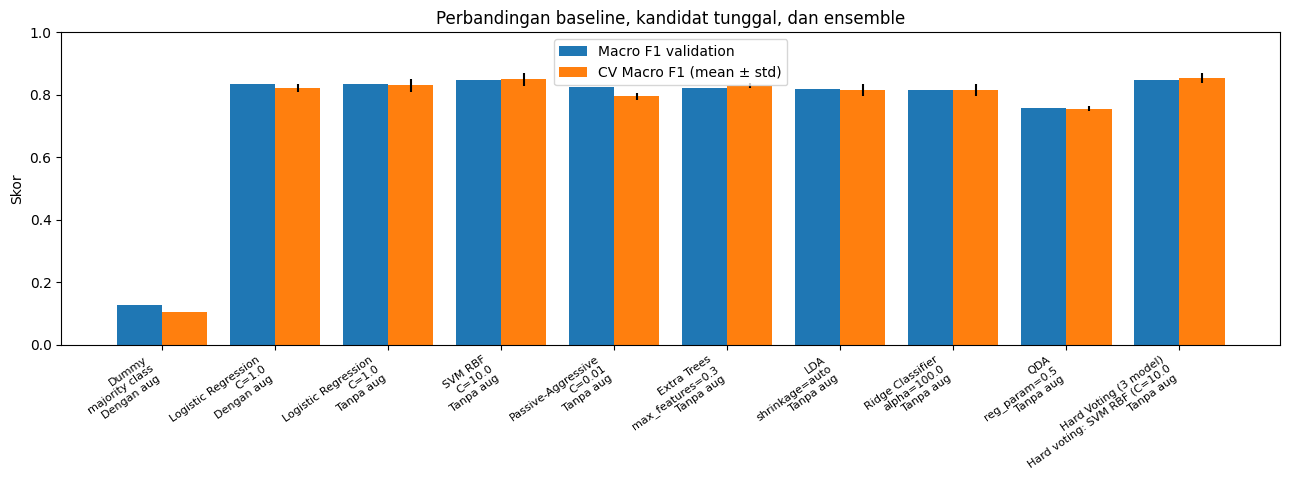

Metrik test hanya ditampilkan untuk baseline pembanding dan satu model final terpilih.


In [ ]:
# H. Gabungkan hasil, pilih model final dari validation, lalu lakukan evaluasi test

tabel_hasil = pd.DataFrame(hasil_val)
pilihan_model = tabel_hasil[tabel_hasil["Tahap"].isin(["Kandidat", "Ensemble"])]
terpilih = pilihan_model.sort_values(urut, ascending=False).iloc[0]

def fit_baris(r):
    X_l, y_l = latih(r["Data latih"])
    if r["Tahap"] == "Ensemble":
        return buat_ensemble(y_l).fit(X_l, y_l)
    return buat_model(r["Model"], r["Nilai"], y_l).fit(X_l, y_l)

# Tahap test: dua baseline pembanding dan satu model final yang sudah dipilih dari validation.
model_final = None
pred_final_val = None
pred_final_test = None
for i, r in tabel_hasil.iterrows():
    is_baseline = r["Tahap"] == "Baseline"
    is_final = (r["Tahap"] == terpilih["Tahap"] and r["Model"] == terpilih["Model"])
    if is_baseline or is_final:
        model_dilatih = fit_baris(r)
        pred_test = model_dilatih.predict(X_te)
        mt = metrik(y_te, pred_test)
        for nama_metrik, nilai_metrik in mt.items():
            tabel_hasil.loc[i, f"{nama_metrik} (test)"] = nilai_metrik
        if is_final:
            model_final = model_dilatih
            pred_final_val = model_final.predict(X_va)
            pred_final_test = pred_test

if model_final is None or pred_final_test is None:
    raise RuntimeError("Model final/prediksi test tidak terbentuk. Periksa proses pemilihan model.")

tabel_hasil["Metode evaluasi"] = "Hold-out validation + Stratified 5-Fold CV (train); test di tahap akhir"
kolom = [
    "Tahap", "Model", "Konfigurasi", "Data latih", "Metode evaluasi",
    "Accuracy", "Balanced Acc", "Macro F1", "CV Macro F1 (mean)", "CV Macro F1 (std)",
    "Macro F1 (test)", "Balanced Acc (test)", "Accuracy (test)",
]
tabel_hasil = tabel_hasil[kolom].rename(columns={
    "Accuracy": "Accuracy (val)", "Balanced Acc": "Balanced Acc (val)", "Macro F1": "Macro F1 (val)"
})
tabel_hasil.to_csv("hasil_eksperimen_awal.csv", index=False)
display(tabel_hasil.round(4).fillna("-"))
print(
    f"Model final dipilih berdasarkan validation: {terpilih['Model']} [{terpilih['Tahap']}], "
    f"skenario data latih: {terpilih['Data latih']}"
)

# Grafik validation dan CV. Test tidak dipakai untuk memilih model.
p = tabel_hasil.copy()
p["label"] = (p["Model"] + "\n" + p["Konfigurasi"].astype(str).str.slice(0, 28)
              + "\n" + p["Data latih"].str.replace("aug_noise", "aug"))
x = np.arange(len(p))
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x - 0.2, p["Macro F1 (val)"], 0.4, label="Macro F1 validation")
ax.bar(x + 0.2, p["CV Macro F1 (mean)"], 0.4,
       yerr=p["CV Macro F1 (std)"], label="CV Macro F1 (mean ± std)")
ax.set_xticks(x); ax.set_xticklabels(p["label"], rotation=35, ha="right", fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Perbandingan baseline, kandidat tunggal, dan ensemble")
ax.set_ylabel("Skor"); ax.legend()
plt.tight_layout(); plt.show()
print("Metrik test hanya ditampilkan untuk baseline pembanding dan satu model final terpilih.")

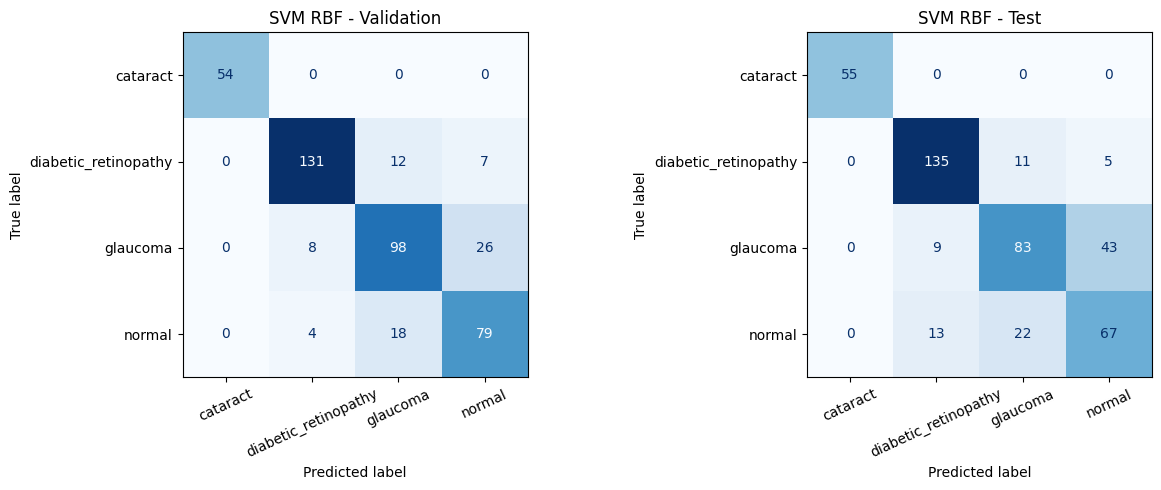

In [ ]:
# Confusion matrix memakai prediksi model final yang sudah dihitung pada bagian H.
model_t = model_final
pred_va, pred_te = pred_final_val, pred_final_test
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nm, yt, yp) in zip(axes, [("Validation", y_va, pred_va), ("Test", y_te, pred_te)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp, labels=LABEL_ORDER), display_labels=LABEL_ORDER).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{terpilih['Model']} - {nm}"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# I. Diagnosis Awal

Diagnosis digunakan untuk menjelaskan mengapa model menghasilkan performa tertentu: kelas yang paling sulit, pola kesalahan, kontribusi kelompok fitur, serta pengaruh subset citra bernama `aug_noise_*`. Analisis pemilihan/diagnosis utama memakai validation. Metrik test pada subbagian I.a hanya melaporkan kembali hasil prediksi yang telah disimpan di H; hasil test tidak digunakan untuk mengubah pilihan model.

In [ ]:
# I.a. Kinerja per kelas dan pasangan kesalahan terbanyak

def tabel_kelas(y_true, y_pred):
    laporan = classification_report(
        y_true, y_pred, labels=LABEL_ORDER, output_dict=True, zero_division=0
    )
    return pd.DataFrame(laporan).T.loc[LABEL_ORDER]

kv = tabel_kelas(y_va, pred_va)
kt = tabel_kelas(y_te, pred_te)
display(pd.concat({
    "Validation": kv[["precision", "recall", "f1-score", "support"]],
    "Test (prediksi tersimpan dari H)": kt[["precision", "recall", "f1-score", "support"]],
}, axis=1).round(3))

cm = pd.DataFrame(confusion_matrix(y_va, pred_va, labels=LABEL_ORDER),
                  index=LABEL_ORDER, columns=LABEL_ORDER)
salah = (
    cm.stack().rename("jumlah").reset_index()
    .set_axis(["Aktual", "Diprediksi", "jumlah"], axis=1)
    .query("Aktual != Diprediksi and jumlah > 0")
    .sort_values("jumlah", ascending=False)
)
print("Kesalahan terbanyak pada validation:")
display(salah.head(5).reset_index(drop=True) if len(salah) else Markdown("Tidak ada kesalahan pada validation."))

Validation                         Test (prediksi tersimpan dari H)                        
                      precision recall f1-score support                        precision recall f1-score support
cataract                  1.000  1.000    1.000    54.0                            1.000  1.000    1.000    55.0
diabetic_retinopathy      0.916  0.873    0.894   150.0                            0.860  0.894    0.877   151.0
glaucoma                  0.766  0.742    0.754   132.0                            0.716  0.615    0.661   135.0
normal                    0.705  0.782    0.742   101.0                            0.583  0.657    0.618   102.0

Kesalahan terbanyak pada validation:


,Aktual,Diprediksi,jumlah
0,glaucoma,normal,26
1,normal,glaucoma,18
2,diabetic_retinopathy,glaucoma,12
3,glaucoma,diabetic_retinopathy,8
4,diabetic_retinopathy,normal,7


,Jumlah,Penurunan Macro F1 (mean),Std
Kelompok fitur,,,
hog,324,0.5157,0.0210
warna,12,0.1001,0.0165
tekstur,14,0.0751,0.0128
ketajaman,6,0.0166,0.0071


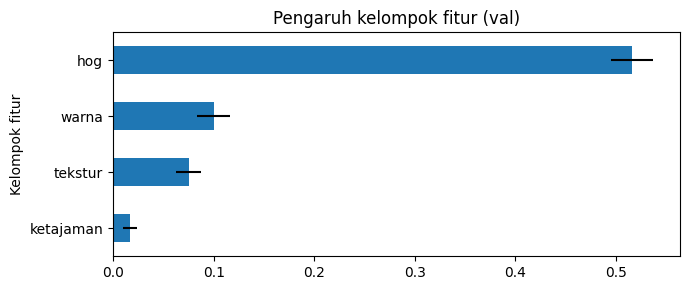

In [ ]:
# I.b. Pengaruh kelompok fitur: permutation importance per KELOMPOK (acak satu kelompok sekaligus, di validation)
rng = np.random.default_rng(RANDOM_STATE)
dasar = f1_score(y_va, pred_va, average="macro"); baris = []
for g, cols in GRUP.items():
    cols = [c for c in cols if c in FITUR_MODEL]
    if not cols: continue
    turun = []
    for _ in range(10):
        Xp = X_va.copy(); Xp[cols] = X_va[cols].to_numpy()[rng.permutation(len(Xp))]
        turun.append(dasar - f1_score(y_va, model_t.predict(Xp), average="macro"))
    baris.append({"Kelompok fitur": g, "Jumlah": len(cols), "Penurunan Macro F1 (mean)": np.mean(turun), "Std": np.std(turun)})
imp = pd.DataFrame(baris).sort_values("Penurunan Macro F1 (mean)", ascending=False).set_index("Kelompok fitur")
display(imp.round(4))
imp["Penurunan Macro F1 (mean)"].plot(kind="barh", xerr=imp["Std"], figsize=(7, 3), title="Pengaruh kelompok fitur (val)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

In [ ]:
# I.c. Ablation aug_noise dan analisis sensitivitas klasifikasi 4 kelas vs 3 kelas
abl = tabel_grid.groupby(["Model", "Data latih"])["Macro F1"].max().unstack().reindex(columns=SKENARIO)
abl["Selisih (dengan - tanpa)"] = abl["Dengan aug_noise"] - abl["Tanpa aug_noise"]
print("Macro F1 validation terbaik per model, dengan vs tanpa aug_noise:")
display(abl.round(4))

# Analisis tiga kelas dilakukan pada OBSERVASI VALIDATION YANG SAMA.
# Skor 4-kelas penuh tidak dibandingkan langsung dengan skor subset 3-kelas.
fundus = ["diabetic_retinopathy", "glaucoma", "normal"]
X_l, y_l = latih(terpilih["Data latih"])
mask_train_fundus = y_l.isin(fundus)
mask_val_fundus = y_va.isin(fundus)
if mask_train_fundus.sum() == 0 or mask_val_fundus.sum() == 0:
    raise ValueError("Tidak cukup observasi untuk analisis sensitivitas tiga kelas.")

if terpilih["Tahap"] == "Ensemble":
    model_tiga_kelas = buat_ensemble(y_l[mask_train_fundus]).fit(
        X_l.loc[mask_train_fundus], y_l[mask_train_fundus]
    )
else:
    model_tiga_kelas = buat_model(terpilih["Model"], terpilih["Nilai"],
                                  y_l[mask_train_fundus]).fit(
        X_l.loc[mask_train_fundus], y_l[mask_train_fundus]
    )

# 4-kelas penuh: semua kelas, semua observasi validation.
f1_4kelas_penuh = f1_score(y_va, pred_va, average="macro", labels=LABEL_ORDER, zero_division=0)
# 4-kelas pada subset fundus: kelas cataract tidak ada di y_true, tetapi prediksi cataract tetap merupakan kesalahan.
f1_4kelas_subset = f1_score(
    y_va[mask_val_fundus], pred_va[mask_val_fundus],
    labels=fundus, average="macro", zero_division=0
)
# Model tiga kelas dilatih ulang tanpa label cataract, dievaluasi pada subset validation yang sama.
pred_tiga_kelas = model_tiga_kelas.predict(X_va.loc[mask_val_fundus])
f1_3kelas_subset = f1_score(
    y_va[mask_val_fundus], pred_tiga_kelas,
    labels=fundus, average="macro", zero_division=0
)

tabel_sensitivitas = pd.DataFrame([
    {"Model/ruang evaluasi": "Model final 4 kelas — seluruh validation", "Jumlah observasi": len(y_va), "Macro F1": f1_4kelas_penuh},
    {"Model/ruang evaluasi": "Model final 4 kelas — subset 3 kelas fundus", "Jumlah observasi": int(mask_val_fundus.sum()), "Macro F1": f1_4kelas_subset},
    {"Model/ruang evaluasi": "Model dilatih ulang 3 kelas — subset validation yang sama", "Jumlah observasi": int(mask_val_fundus.sum()), "Macro F1": f1_3kelas_subset},
]).set_index("Model/ruang evaluasi")
display(tabel_sensitivitas.round(4))
print(f"F1 kelas cataract pada model final 4 kelas (validation): {kv.loc['cataract', 'f1-score']:.4f}")
print(
    "Interpretasi: perbandingan dua baris subset memakai observasi dan tiga label target yang sama. "
    "Perbedaan skor tetap bersifat diagnostik/eksploratif, bukan bukti kausal bahwa kelas cataract menaikkan atau menurunkan skor. "
    "Model tiga kelas memiliki ruang label dan jumlah data latih berbeda."
)

Macro F1 validation terbaik per model, dengan vs tanpa aug_noise:


Data latih,Dengan aug_noise,Tanpa aug_noise,Selisih (dengan - tanpa)
Model,,,
Extra Trees,0.8133,0.8218,-0.0084
LDA,0.8094,0.8188,-0.0094
Passive-Aggressive,0.8100,0.8243,-0.0142
QDA,0.7525,0.7570,-0.0045
Ridge Classifier,0.8097,0.8140,-0.0042
SVM RBF,0.8436,0.8475,-0.0038


,Jumlah observasi,Macro F1
Model/ruang evaluasi,,
Model final 4 kelas — seluruh validation,437,0.8475
Model final 4 kelas — subset 3 kelas fundus,383,0.7966
Model dilatih ulang 3 kelas — subset validation yang sama,383,0.7869


F1 kelas cataract pada model final 4 kelas (validation): 1.0000
Interpretasi: perbandingan dua baris subset memakai observasi dan tiga label target yang sama. Perbedaan skor tetap bersifat diagnostik/eksploratif, bukan bukti kausal bahwa kelas cataract menaikkan atau menurunkan skor. Model tiga kelas memiliki ruang label dan jumlah data latih berbeda.


In [ ]:
# I.d. Ringkasan temuan otomatis dari hasil eksperimen
b_lr = tabel_hasil[(tabel_hasil["Model"] == "Logistic Regression") &
                   (tabel_hasil["Data latih"] == terpilih["Data latih"])].iloc[0]
b_du = tabel_hasil[tabel_hasil["Model"] == "Dummy"].iloc[0]
baris_final = tabel_hasil[
    (tabel_hasil["Model"] == terpilih["Model"]) &
    (tabel_hasil["Tahap"] == terpilih["Tahap"])
].iloc[0]
sulit = kv["f1-score"].idxmin()
kesalahan_terbanyak = (
    f"{salah.iloc[0]['Aktual']} → {salah.iloc[0]['Diprediksi']} ({int(salah.iloc[0]['jumlah'])} citra)"
    if len(salah) else "tidak ada kesalahan pada validation"
)

jumlah_aug_baik = int((abl["Selisih (dengan - tanpa)"] > 0).sum())
jumlah_aug_buruk = int((abl["Selisih (dengan - tanpa)"] < 0).sum())
jumlah_aug_seri = int(((abl["Selisih (dengan - tanpa)"]).abs() <= 1e-12).sum())
kelompok_terpenting = imp.index[0] if len(imp) else "belum dapat dihitung"

narasi_ringkasan = f"""
**Ringkasan hasil eksperimen awal**

- Model final yang dipilih berdasarkan Macro F1 validation: **{terpilih['Model']} ({terpilih['Tahap']})**, konfigurasi **{terpilih['Konfigurasi']}**, skenario **{terpilih['Data latih']}**.
- Kinerja model final: Macro F1 validation **{baris_final['Macro F1 (val)']:.4f}**; CV Macro F1 **{baris_final['CV Macro F1 (mean)']:.4f} ± {baris_final['CV Macro F1 (std)']:.4f}**; Macro F1 test **{baris_final['Macro F1 (test)']:.4f}**.
- Baseline validation: Dummy Macro F1 **{b_du['Macro F1 (val)']:.4f}** dan Logistic Regression **{b_lr['Macro F1 (val)']:.4f}**. Selisih model final terhadap Logistic Regression adalah **{baris_final['Macro F1 (val)'] - b_lr['Macro F1 (val)']:+.4f}**.
- Kelas dengan F1 validation terendah: **{sulit}** ({kv.loc[sulit, 'f1-score']:.3f}). Pasangan kesalahan terbanyak: **{kesalahan_terbanyak}**.
- Kelompok fitur dengan penurunan Macro F1 terbesar ketika dipermutasi: **{kelompok_terpenting}**.
- Pada {len(abl)} keluarga model, skenario dengan `aug_noise_*` lebih baik pada {jumlah_aug_baik}, lebih buruk pada {jumlah_aug_buruk}, dan setara pada {jumlah_aug_seri} model menurut validation. Hasil ini eksploratif dan bergantung pada satu validation split.
- Analisis sensitivitas 3-kelas: Macro F1 model 4-kelas pada subset fundus yang sama **{f1_4kelas_subset:.4f}**, sedangkan model yang dilatih ulang sebagai 3-kelas **{f1_3kelas_subset:.4f}**. Ini perbandingan diagnostik pada subset yang sama, bukan bukti kausal bahwa kelas cataract menggelembungkan skor.
"""
display(Markdown(narasi_ringkasan))


**Ringkasan hasil eksperimen awal**

- Model final yang dipilih berdasarkan Macro F1 validation: **SVM RBF (Kandidat)**, konfigurasi **C=10.0**, skenario **Tanpa aug_noise**.
- Kinerja model final: Macro F1 validation **0.8475**; CV Macro F1 **0.8497 ± 0.0206**; Macro F1 test **0.7889**.
- Baseline validation: Dummy Macro F1 **0.1278** dan Logistic Regression **0.8353**. Selisih model final terhadap Logistic Regression adalah **+0.0121**.
- Kelas dengan F1 validation terendah: **normal** (0.742). Pasangan kesalahan terbanyak: **glaucoma → normal (26 citra)**.
- Kelompok fitur dengan penurunan Macro F1 terbesar ketika dipermutasi: **hog**.
- Pada 6 keluarga model, skenario dengan `aug_noise_*` lebih baik pada 0, lebih buruk pada 6, dan setara pada 0 model menurut validation. Hasil ini eksploratif dan bergantung pada satu validation split.
- Analisis sensitivitas 3-kelas: Macro F1 model 4-kelas pada subset fundus yang sama **0.7966**, sedangkan model yang dilatih ulang sebagai 3-kelas **0.7869**. Ini perbandingan diagnostik pada subset yang sama, bukan bukti kausal bahwa kelas cataract menggelembungkan skor.


**Analisis dan Keputusan Model**

1. **Model final belum terbukti lebih baik dari baseline.** Dengan data latih yang sama (tanpa `aug_noise_*`), SVM RBF hanya unggul tipis atas Logistic Regression di validation (Macro F1 0,8475 vs 0,8353; +0,012), tetapi di test justru lebih rendah (0,7889 vs 0,8154). Selisih 0,012 lebih kecil daripada simpangan baku CV SVM (0,0206) dan LR (0,0211), dan validation dipakai untuk memilih dari 32 konfigurasi sehingga cenderung optimistik. Keputusan: SVM tetap kandidat utama tetapi belum dikunci; UAS membandingkannya lagi dengan Logistic Regression yang di-tuning dan dengan group CV.
2. **SVM dan Hard Voting setara.** Macro F1 validation 0,8475 vs 0,8474 dengan Accuracy sama (0,8284). CV ensemble 0,8534 ± 0,0157 vs SVM 0,8497 ± 0,0206. SVM dipilih karena aturan yang ditetapkan sebelumnya (Macro F1 validation tertinggi) dan modelnya lebih sederhana. Ensemble tetap dibawa ke UAS.
3. **Skor 4 kelas dinaikkan oleh cataract.** Cataract F1 = 1,000 di validation dan test. Pada subset 3 kelas fundus, Macro F1 hanya 0,7966 (model 4-kelas) dan 0,7869 (model dilatih ulang 3-kelas), dibanding 0,8475 pada seluruh validation. Kemampuan membedakan penyakit retina yang realistis ada di kisaran 0,79–0,80.
4. **Kesulitan ada pada glaucoma dan normal** (F1 test 0,661 dan 0,618). Kesalahan terbanyak di validation: glaucoma→normal (26) dan normal→glaucoma (18). Hipotesis: fitur global (warna, tekstur, HOG 64×64) tidak menangkap perubahan cup/disc optik pada glaukoma. Ini akan diuji di UAS dengan fitur wilayah optic disc.
5. **HOG paling berpengaruh:** permutasi HOG menurunkan Macro F1 sebesar 0,516, jauh di atas warna (0,100), tekstur (0,075), dan ketajaman (0,017). Perbandingan ini sebagian dipengaruhi jumlah fitur per kelompok (324 vs 6–14).
6. **Tanpa `aug_noise_*` lebih baik pada 6 dari 6 keluarga model**, dengan selisih kecil (0,004–0,014) pada satu split validation. Ini indikasi, bukan bukti.

**Keterbatasan dan hal yang perlu ditindaklanjuti**

1. **Shortcut learning pada kelas cataract (terkonfirmasi).** Cataract berupa foto mata bagian luar, sedangkan tiga kelas lain berupa citra fundus, sehingga model dapat memisahkannya hanya dari jenis citra. Skor 4 kelas tidak boleh dibaca sebagai kemampuan mendeteksi penyakit; skor 3 kelas fundus lebih representatif.
2. **Split belum berbasis pasien atau sumber citra.** Citra asli dan turunannya dapat berada pada fold berbeda sehingga CV acak berpotensi optimistik. UAS perlu mengidentifikasi grup sumber dan mempertimbangkan `StratifiedGroupKFold`.
3. **Audit duplikasi menggunakan informasi lintas split.** Test tidak dihapus, tetapi hash/kemiripannya dipakai untuk mengeluarkan pasangan duplikat dari train/validation. Ini transparan untuk audit kebocoran, tetapi berarti test bukan *blind* selama tahap kurasi.
4. **Pemilihan fitur dilakukan dengan CV training dan pemilihan konfigurasi dilakukan pada validation.** CV yang dilaporkan untuk konfigurasi terpilih merupakan indikator stabilitas, bukan estimasi bebas bias dari keseluruhan proses seleksi. Nested CV/group CV dapat ditambahkan pada UAS.
5. **Label dan fitur bersifat dataset-level.** Label belum diverifikasi oleh tenaga medis dan fitur warna/tekstur/ketajaman/HOG bukan representasi klinis lengkap. Model bukan alat diagnosis.
6. **Pencarian hyperparameter masih terbatas** dan memakai satu validation split untuk perbandingan banyak konfigurasi. Ensemble yang diuji baru hard voting; soft voting, bagging, stacking, kalibrasi, dan analisis error visual lebih lanjut menjadi pekerjaan berikutnya.

# J. Rencana Pengembangan Setelah UTS

| No. | Pekerjaan | Tujuan | Keluaran |
|---|---|---|---|
| 1 | Verifikasi Project ID/status registry, sumber dan modalitas citra tiap kelas; diskusikan potensi *shortcut* dengan dosen. | Memastikan identitas proyek dan interpretasi masalah/data tepat. | Metadata proyek dan keputusan metodologis. |
| 2 | Telusuri citra asli dan turunan augmentasi; bentuk grup sumber/pasien/keluarga augmentasi bila informasinya tersedia, lalu evaluasi dengan `StratifiedGroupKFold`. | Mengurangi kebocoran antar-fold. | Tabel CV berbasis grup dan perbandingan dengan CV awal. |
| 3 | Perluas feature engineering: LBP multi-radius, histogram warna, fitur wilayah optic disc/pembuluh darah, seleksi fitur, dan PCA yang berada di dalam pipeline. | Menguji representasi fitur yang lebih relevan. | Hasil ablation fitur. |
| 4 | Lakukan tuning sistematis pada model teratas dengan CV/nested CV di training. | Mengurangi bias akibat pemilihan konfigurasi pada satu validation split. | Log tuning dan estimasi performa yang lebih kuat. |
| 5 | Bandingkan soft voting, bagging, atau stacking dengan hard voting dan model tunggal terbaik. | Menilai apakah ensemble memberi peningkatan yang konsisten. | Tabel perbandingan model tunggal dan ensemble. |
| 6 | Lakukan analisis error visual, kalibrasi probabilitas, dan evaluasi recall/F1 per kelas. | Memahami pola kegagalan dan kepercayaan prediksi. | Dokumentasi error analysis. |
| 7 | Kunci pipeline dan model sebelum evaluasi test final, lalu finalisasi notebook, repository, laporan, dan presentasi/defense. | Menyiapkan penyelesaian proyek UAS yang dapat direproduksi. | Artefak final dan dokumentasi eksperimen. |
| 8 | Pisahkan evaluasi cataract dari tiga kelas fundus (atau cari citra fundus untuk cataract); tangani `lap_var` yang sangat miring (mis. transformasi log); bandingkan ulang Logistic Regression yang di-tuning dengan SVM. | Menghindari skor yang digelembungkan oleh perbedaan modalitas dan mengonfirmasi model terbaik. | Skor 3 kelas fundus sebagai skor utama dan tabel perbandingan LR vs SVM. |

## Peta Artefak dan Reproduksi

| Bagian notebook | Isi | Artefak |
|---|---|---|
| C.1a | Matriks fitur (5.772 citra × 356 fitur) beserta label dan split | `fitur_mata_model.zip` (berisi `fitur_mata_model.csv`) |split | `fitur_mata_model.csv` |
| E | Hasil 32 konfigurasi tuning (validation) | `catatan_eksperimen_tuning.csv` |
| G | Perbandingan baseline, kandidat, dan ensemble (validation + CV) | `perbandingan_ensemble_awal.csv` |
| H | Hasil akhir validation, CV, dan test | `hasil_eksperimen_awal.csv` |

Grafik dan tabel lain tersimpan sebagai output notebook ini.

**Repository:** (https://github.com/lycaonstar/prediksi-kelainan-mata)  |   
**Laporan:** (Laporan_UTS.pdf)

**Cara mereproduksi:** buka notebook di Google Colab (runtime CPU) → *Runtime → Run all*. Dataset diunduh otomatis lewat `kagglehub` (`mahin661/eye-disease-classification-fundus-image-dataset`). Seed = 42. Versi pustaka dicatat pada sel terakhir dan pada `requirements.txt` di repository. File CSV dibuat di penyimpanan sementara Colab; unduh dan simpan pada folder `artifacts/` di repository.

In [ ]:
# Berkas keluaran dan informasi lingkungan untuk dokumentasi eksperimen
import skimage, joblib

berkas_hasil = [
    "fitur_mata_model.csv",
    "catatan_eksperimen_tuning.csv",
    "perbandingan_ensemble_awal.csv",
    "hasil_eksperimen_awal.csv",
]
for nama in berkas_hasil:
    print(f"{nama:36s} {'ADA' if os.path.exists(nama) else 'BELUM TERBENTUK'}")
print("\nSeed:", RANDOM_STATE)
print("Python:", platform.python_version())
print("numpy:", np.__version__, "| pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__, "| scikit-image:", skimage.__version__)
print("OpenCV:", cv2.__version__, "| joblib:", joblib.__version__)
print("Dataset: mahin661/eye-disease-classification-fundus-image-dataset | lokasi:", DATA_DIR)
print("Jumlah citra akhir preprocessing:", len(d2))
print("Jumlah fitur:", len(SEMUA), "| fitur yang dipakai:", len(FITUR_MODEL))
print("Catatan: CSV akan terbentuk setelah seluruh sel terkait berhasil dijalankan.")

fitur_mata_model.csv                 ADA
catatan_eksperimen_tuning.csv        ADA
perbandingan_ensemble_awal.csv       ADA
hasil_eksperimen_awal.csv            ADA

Seed: 42
Python: 3.13.18
numpy: 2.4.6 | pandas: 2.2.3
scikit-learn: 1.6.1 | scikit-image: 0.25.2
OpenCV: 5.0.0 | joblib: 1.6.0
Dataset: mahin661/eye-disease-classification-fundus-image-dataset | lokasi: /kaggle/input/eye-disease-classification-fundus-image-dataset
Jumlah citra akhir preprocessing: 5772
Jumlah fitur: 356 | fitur yang dipakai: 356
Catatan: CSV akan terbentuk setelah seluruh sel terkait berhasil dijalankan.
